# A Machine Learning–Driven Predictive and Prescriptive Analytics Framework for Forecasting Weekly Production Target Achievement in the Shoe Manufacturing Division of DI Leather

# 2. Exploratory Data Analysis (EDA)

Exploratory Data Analysis (EDA) is performed to understand the structure, quality, distribution, and relationships within the weekly production dataset before developing machine learning models.

The main objective is to investigate production patterns and identify variables that may help predict `actual_qty`, which represents the actual production quantity. The analysis also examines temporal variations, categorical production characteristics, and relationships between numerical variables.

The analysis is organised into the following sections:

1. Setup and data loading.
2. Dataset overview and data integrity.
3. Target variable analysis.
4. Temporal patterns.
5. Categorical production drivers.
6. Numerical relationships and correlation.
7. Key findings and implications for machine learning.

The findings will guide feature selection, model development, and the evaluation of predictive performance. Any relationships identified during EDA will be treated as exploratory evidence rather than proof of causation.

This notebook explores `DI_Leather_preprocessed.csv` (9,495 weekly production records, 22 columns, 207 weeks from Apr 2022 to Mar 2026) before feature engineering and modeling.




## 2.1 Setup and Data Loading

This section prepares the environment for exploratory data analysis by importing the required Python libraries and loading the preprocessed production dataset.

Pandas and NumPy are used for data manipulation and numerical calculations, while Matplotlib and Seaborn support graphical analysis. Display settings are configured to make the dataset and analysis outputs easier to inspect.

The dataset is loaded into a Pandas DataFrame so that its columns, records, and production characteristics can be examined. Correct data handling at this stage is important because subsequent statistical summaries and visualisations depend on the values being represented appropriately.


In [78]:
# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

# Plot settings
sns.set_theme(style="whitegrid")

# Warnings
import warnings
warnings.filterwarnings('ignore')

### 2.1.1 Load the Dataset and Prepare Date Columns

The preprocessed dataset is loaded from `DI_Leather_preprocessed.csv`.

The `week_start_date` and `week_end_date` columns are converted into datetime format. This ensures that the date values can be used for chronological grouping, sorting, and time-based visualisation.

Date information is particularly important in production forecasting because observations must be understood in their correct temporal order. The prepared dates will be used to investigate weekly production trends and differences across financial months and financial years.

This step prepares the dataset for EDA without changing the production quantities or other feature values.


In [79]:

# Load the preprocessed dataset
df = pd.read_csv('../data/processed/DI_Leather_preprocessed.csv')

# Convert date columns to datetime format
df['week_start_date'] = pd.to_datetime(df['week_start_date'])
df['week_end_date'] = pd.to_datetime(df['week_end_date'])


## 2.2 Dataset Overview and Data Integrity

This section examines the structure and quality of the dataset to establish whether it is suitable for further analysis.

Data integrity checks help identify missing values, duplicate records, constant variables, invalid production quantities, and inconsistencies in calculated fields. These issues can affect statistical summaries and may reduce the reliability of machine learning models if they are not properly understood.

The following checks are performed:

1. Dataset structure and sample records.
2. Data types, unique values, and missing values.
3. Duplicate records.
4. Descriptive statistics.
5. Categorical value distributions.
6. Time coverage.
7. Validity of planned and actual quantities.
8. Consistency of the production-gap calculation.

The results provide an overview of the dataset and help identify considerations that must be addressed before model development.


### 2.2.1 Dataset Structure and First/Last Records

The structure of the dataset is examined using `df.info()`, while the first and last records are displayed using `df.head()` and `df.tail()`.

The structural summary provides information about the number of records, column names, data types, and non-null values. The first records provide an initial view of how production information is organised, while the last records help inspect the observations at the end of the dataset.

Examining both ends of the dataset is useful for understanding the available variables, checking date fields, and identifying any immediately visible inconsistencies.

This initial inspection establishes a foundation for the more detailed data quality and statistical checks that follow.

In [80]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9495 entries, 0 to 9494
Data columns (total 22 columns):
 #   Column                        Non-Null Count  Dtype         
---  ------                        --------------  -----         
 0   financial_year                9495 non-null   str           
 1   financial_month               9495 non-null   str           
 2   week_no                       9495 non-null   int64         
 3   week_of_month                 9495 non-null   int64         
 4   week_start_date               9495 non-null   datetime64[us]
 5   week_end_date                 9495 non-null   datetime64[us]
 6   factory_unit                  9495 non-null   str           
 7   product_family                9495 non-null   str           
 8   item_name                     9495 non-null   str           
 9   size_id                       9495 non-null   int64         
 10  grade                         9495 non-null   str           
 11  planned_qty                   9495 non-nu

In [81]:
display(df.head())
display(df.tail())

,financial_year,financial_month,week_no,week_of_month,week_start_date,week_end_date,factory_unit,product_family,item_name,size_id,grade,planned_qty,rate,actual_qty,no_of_workers,working_hours,total_duration_per_shoe_mins,machine_capacity_per_day,machine_count,production_gap_qty,bottleneck_flag,order_category
0,2022-2023,Apr,3,3,2022-04-18,2022-04-22,Factory Unit 01,Ladies,BINOLI (VAST) - BROWN,12,A,35,4363.35,38,15,647.82,114.50,200,5,-3,True,Others
1,2022-2023,Apr,3,3,2022-04-18,2022-04-22,Factory Unit 01,Ladies,BINOLI - L - BLACK,7,A,41,4870.92,33,23,844.78,123.14,200,5,8,True,Others
2,2022-2023,Apr,3,3,2022-04-18,2022-04-22,Factory Unit 01,Ladies,BINOLI - L - GREEN,9,A,15,7003.71,44,15,673.07,89.04,200,3,-29,False,Others
3,2022-2023,Apr,3,3,2022-04-18,2022-04-22,Factory Unit 01,Gents,BOOT HIGH LEG - BLACK,13,A,5,4676.91,31,11,550.89,125.18,200,3,-26,False,Forces/Police
4,2022-2023,Apr,3,3,2022-04-18,2022-04-22,Factory Unit 01,Gents,BOOT HIGH LEG - L - BLACK,13,A,11,3803.13,36,18,813.02,117.33,200,5,-25,True,Forces/Police


,financial_year,financial_month,week_no,week_of_month,week_start_date,week_end_date,factory_unit,product_family,item_name,size_id,grade,planned_qty,rate,actual_qty,no_of_workers,working_hours,total_duration_per_shoe_mins,machine_capacity_per_day,machine_count,production_gap_qty,bottleneck_flag,order_category
9490,2025-2026,Mar,52,5,2026-03-30,2026-04-03,Factory Unit 01,Gents,TONI - PINK,13,A,8,7591.49,28,18,737.42,119.46,200,3,-20,False,Others
9491,2025-2026,Mar,52,5,2026-03-30,2026-04-03,Factory Unit 01,Gents,ZURI - RED,6,A,39,7763.55,35,17,716.24,137.40,200,6,4,True,Others
9492,2025-2026,Mar,52,5,2026-03-30,2026-04-03,Factory Unit 01,Gents,[SAMPLE] SHOE GENTS - BLACK,8,A,9,4183.72,38,14,614.79,118.66,200,5,-29,False,Others
9493,2025-2026,Mar,52,5,2026-03-30,2026-04-03,Factory Unit 02 - LGF,Gents,STELLA - GREEN,13,A,46,7704.58,35,24,944.45,144.68,200,4,11,False,Others
9494,2025-2026,Mar,52,5,2026-03-30,2026-04-03,Factory Unit 02 - LGF,Gents,TRUE MOCCACINO - L - BLACK,8,A,5,4517.57,24,16,637.79,129.95,200,3,-19,False,Others


### 2.2.2 Data Types, Unique Values, and Missing Values

A summary table is created to examine the data type, number of unique values, and number of missing values in each column.

- **Data type:** Indicates whether a column contains numerical values, text, Boolean values, or another data representation.
- **Unique values:** Shows the number of distinct values in a column. This helps identify categorical variables, variables with many distinct values, and columns that contain only one value.
- **Missing values:** Shows how many records do not contain a value for each column.

These checks help determine how variables should be handled in later stages. Numerical variables can be examined using descriptive statistics and correlation analysis, while categorical variables can be compared by group and may require encoding before being used by machine learning algorithms.

The summary also helps identify constant columns and variables with many distinct categories that may require special consideration during feature selection.

In [82]:
dtype_summary = pd.DataFrame({
    'Data Type': df.dtypes,
    'Unique Values': df.nunique(),
    'Missing Values': df.isnull().sum()
})

dtype_summary

,Data Type,Unique Values,Missing Values
financial_year,str,4,0
financial_month,str,12,0
week_no,int64,53,0
week_of_month,int64,5,0
week_start_date,datetime64[us],207,0
week_end_date,datetime64[us],207,0
factory_unit,str,3,0
product_family,str,2,0
item_name,str,370,0
size_id,int64,8,0


#### 2.2.2.1 Identify Constant Columns

The `machine_capacity_per_day` column contains only one unique value: 200.

A constant column has the same value across all observations and therefore provides no variation for distinguishing between production records. As a result, it cannot explain differences in actual production quantity through a statistical relationship.

Although machine capacity may be relevant to manufacturing operations, this column does not capture differences between the observations in the current dataset.

It is therefore excluded from the numerical correlation analysis and would generally be excluded from the model predictors because it provides no information for distinguishing between predictions.


### 2.2.3 Duplicate Records

The number of exact duplicate rows is calculated using `df.duplicated()`.

Duplicate records can cause the same observation to be counted more than once, potentially affecting descriptive statistics, visualisations, and model training. Checking for duplicates helps determine whether repeated rows could influence the analysis.

This check identifies rows that are identical across all available columns. It does not determine whether two different records represent the same real-world production activity, because that would require additional knowledge of the production-record structure.

The duplicate count provides a basic data integrity check before proceeding with the remaining EDA.


In [83]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


### 2.2.4 Descriptive Statistics

Descriptive statistics are calculated for the numerical columns using `df.describe().T`.

The summary includes several important measures:

- **Count:** Number of non-missing observations.
- **Mean:** Average value of a variable.
- **Standard deviation:** Degree of variation around the mean.
- **Minimum and maximum:** Smallest and largest recorded values.
- **Quartiles:** Values that divide the observations into four parts.

These measures help explain the scale, spread, and distribution of production quantities and other numerical variables.

Comparing the mean and median is particularly useful when investigating skewness. A substantial difference between these values may indicate that unusually large or small observations influence the average.

The statistics for `planned_qty` show a mean of approximately 38 and a median of 10, suggesting a strongly right-skewed distribution. In comparison, `actual_qty` has a mean of approximately 37 and a median of 34, indicating a more balanced distribution.

These differences help establish how planned and actual production quantities behave before investigating their relationship in greater detail.


In [84]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
week_no,9495.0,26.812533,1.0,14.0,27.0,40.0,53.0,15.008587
week_of_month,9495.0,2.704581,1.0,2.0,3.0,4.0,5.0,1.269149
week_start_date,9495,2024-04-06 03:32:10.236966,2022-04-18 00:00:00,2023-07-03 00:00:00,2024-03-11 00:00:00,2025-01-20 00:00:00,2026-03-30 00:00:00,NaN
week_end_date,9495,2024-04-10 03:32:10.236966,2022-04-22 00:00:00,2023-07-07 00:00:00,2024-03-15 00:00:00,2025-01-24 00:00:00,2026-04-03 00:00:00,NaN
size_id,9495.0,9.499631,6.0,7.0,10.0,12.0,13.0,2.309927
planned_qty,9495.0,38.233807,1.0,5.0,10.0,34.0,1759.0,127.02583
rate,9495.0,5266.926374,935.75,4135.28,5285.2,6574.405,9992.99,1658.775974
actual_qty,9495.0,37.012006,8.0,27.0,34.0,44.0,106.0,13.051706
no_of_workers,9495.0,15.970511,8.0,12.0,15.0,19.0,32.0,4.959704
working_hours,9495.0,657.262174,255.86,487.335,623.96,801.165,1523.99,224.307688


Note the gap between the mean and median of `planned_qty` (≈38 vs 10): planned quantities are heavily right-skewed, while `actual_qty` is much more symmetric (mean ≈37, median 34).


### 2.2.5 Categorical Columns: Value Counts

Value counts are examined for the categorical and Boolean columns, excluding `item_name`.

This analysis shows how frequently each category occurs and helps identify dominant categories, less common categories, and possible imbalances in the observations.

The distribution of categories is important when interpreting group comparisons. For example, an average calculated from a category containing many records may be more stable than an average calculated from a category containing only a few records.

The `item_name` column is examined separately in Section 2.5.2 because it contains 370 distinct values. Analysing it separately provides a more focused way to investigate item-level production quantities without producing an unnecessarily large general value-count summary.


In [85]:
categorical_columns = [
    col for col in df.select_dtypes(include=['object', 'bool']).columns
    if col != 'item_name'
]

for col in categorical_columns:
    print(f"\n{'='*60}")
    print(f"{col}")
    print(f"{'='*60}")
    print(df[col].value_counts())


financial_year
financial_year
2023-2024    3422
2024-2025    2747
2025-2026    1820
2022-2023    1506
Name: count, dtype: int64

financial_month
financial_month
Sep    860
Dec    837
Jan    837
May    829
Mar    825
Oct    821
Jul    820
Jun    801
Nov    739
Apr    718
Aug    705
Feb    703
Name: count, dtype: int64

factory_unit
factory_unit
Factory Unit 01          8921
Factory Unit 02 - LGF     525
Factory Unit 03            49
Name: count, dtype: int64

product_family
product_family
Gents     8277
Ladies    1218
Name: count, dtype: int64

grade
grade
A    9070
B     425
Name: count, dtype: int64

bottleneck_flag
bottleneck_flag
False    5983
True     3512
Name: count, dtype: int64

order_category
order_category
Others           7853
Forces/Police    1455
School            187
Name: count, dtype: int64


`item_name` is excluded here (370 unique values); it is analysed separately in Section 5.

### 2.2.6 Class Distribution and Imbalance Assessment

This section examines the distribution of categorical variables to identify categories that are disproportionately represented in the production dataset. Particular attention is given to `bottleneck_flag`, which indicates whether a production record is associated with a flagged bottleneck.

Because the prediction target, `actual_qty`, is continuous, conventional class imbalance techniques used in classification are not directly applicable to this regression task. Instead, category counts and percentages are examined to identify underrepresented groups that may have limited representation during model training.

An imbalanced predictor distribution does not automatically mean that the model is biased or unsuitable. The findings should be interpreted alongside the number of observations in each category and the model's performance.

,Count,Percentage
bottleneck_flag,,
False,5983,63.01
True,3512,36.99


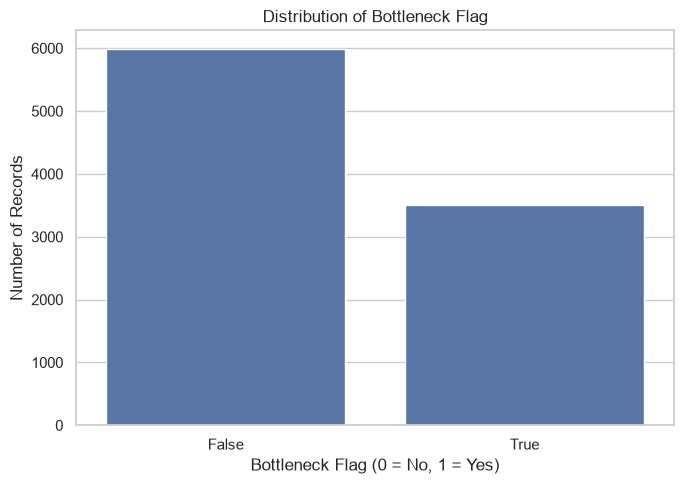


Distribution of financial_month:


,Count,Percentage
financial_month,,
Sep,860,9.06
Dec,837,8.82
Jan,837,8.82
May,829,8.73
Mar,825,8.69
Oct,821,8.65
Jul,820,8.64
Jun,801,8.44
Nov,739,7.78



Distribution of factory_unit:


,Count,Percentage
factory_unit,,
Factory Unit 01,8921,93.95
Factory Unit 02 - LGF,525,5.53
Factory Unit 03,49,0.52



Distribution of product_family:


,Count,Percentage
product_family,,
Gents,8277,87.17
Ladies,1218,12.83


... (2 outputs left out)


Distribution of order_category:


,Count,Percentage
order_category,,
Others,7853,82.71
Forces/Police,1455,15.32
School,187,1.97



Distribution of size_id:


,Count,Percentage
size_id,,
6,1227,12.92
13,1218,12.83
10,1215,12.80
7,1202,12.66
12,1180,12.43
11,1176,12.39
8,1150,12.11
9,1127,11.87


In [86]:

# Assess the distribution of bottleneck_flag
bottleneck_counts = df['bottleneck_flag'].value_counts(dropna=False)
bottleneck_percentages = (
    df['bottleneck_flag'].value_counts(normalize=True, dropna=False) * 100
)

bottleneck_distribution = pd.DataFrame({
    'Count': bottleneck_counts,
    'Percentage': bottleneck_percentages.round(2)
})

display(bottleneck_distribution)

# Visualise the distribution
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x='bottleneck_flag')
plt.title('Distribution of Bottleneck Flag')
plt.xlabel('Bottleneck Flag (0 = No, 1 = Yes)')
plt.ylabel('Number of Records')
plt.tight_layout()
plt.show()

# Examine the representation of categorical variables
categorical_cols = [
    'financial_month', 'factory_unit', 'product_family',
    'grade', 'order_category', 'size_id'
]

for col in categorical_cols:
    print(f"\nDistribution of {col}:")
    display(
        df[col].value_counts(dropna=False)
        .rename('Count')
        .to_frame()
        .assign(
            Percentage=lambda x:
            (x['Count'] / len(df) * 100).round(2)
        )
    )


### 2.2.7 Time Coverage

The earliest production week, latest production week, and number of distinct production weeks are examined using the date columns.

Understanding the time coverage establishes the period represented by the dataset and provides context for interpreting production trends.

The dataset covers production activity from April 2022 to March 2026 and contains 207 distinct production weeks. This allows production patterns to be examined across weekly observations, financial months, financial years, and positions within the month.

Time coverage is also important for model evaluation. Since the project aims to predict production quantities, the training and testing data should be divided chronologically so that future observations are not used to predict earlier periods.


In [87]:
print("Earliest production week:", df['week_start_date'].min())
print("Latest production week:", df['week_end_date'].max())
print("Number of production weeks:", df['week_start_date'].nunique())

Earliest production week: 2022-04-18 00:00:00
Latest production week: 2026-04-03 00:00:00
Number of production weeks: 207


### 2.2.8 Validity Checks on Production Quantities

The dataset is checked for zero and negative values in `planned_qty` and `actual_qty`.

These checks help identify production records that may require further investigation. Negative quantities may indicate recording or data-processing problems, while zero quantities would need to be interpreted according to the manufacturing context.

The results indicate that no zero or negative planned or actual quantities are present. Therefore, no records need to be removed specifically because of these quantity checks.

This conclusion applies only to the two quantities examined. Other variables may still require separate checks depending on their meaning and intended use.


In [88]:
print("Zero planned quantity:", (df['planned_qty'] == 0).sum())
print("Negative planned quantity:", (df['planned_qty'] < 0).sum())
print("Zero actual quantity:", (df['actual_qty'] == 0).sum())
print("Negative actual quantity:", (df['actual_qty'] < 0).sum())

Zero planned quantity: 0
Negative planned quantity: 0
Zero actual quantity: 0
Negative actual quantity: 0


No zero or negative planned/actual quantities exist, so no row needs to be removed for invalid quantities.

### 2.2.9 Production Gap Consistency Check

The production-gap calculation is verified by comparing the recorded `production_gap_qty` against the difference between planned and actual production quantities.

The expected relationship is:

`production_gap_qty = planned_qty - actual_qty`

The difference between the recorded value and the recalculated value is examined for every row. A difference of zero indicates that the stored production gap is consistent with the formula.

The results confirm that the production-gap calculation is consistent throughout the dataset.

However, `production_gap_qty` is derived directly from `planned_qty` and `actual_qty`. Since `actual_qty` is the modelling target, the production-gap column must not be used as a predictor when it would reveal the actual production outcome.

Instead, the production gap can be calculated after predicting actual production quantity to support production planning and prescriptive recommendations.



In [89]:
# Verify the production gap calculation (difference should be 0 for every row)
difference = df['production_gap_qty'] - (df['planned_qty'] - df['actual_qty'])

difference.value_counts().head()

0    9495
Name: count, dtype: int64

Confirms `production_gap_qty = planned_qty − actual_qty` for every row (difference = 0 everywhere). The gap column is therefore derived from the target and must be excluded from the model's features.

## 2.3 Target Variable Analysis: `actual_qty`

The target variable for the machine learning models is `actual_qty`, which represents the actual production quantity recorded for each observation.

Understanding the target variable is essential because the models will be trained to predict this quantity. Its range, central tendency, variability, and distribution can influence model selection, prediction interpretation, and evaluation.

This section examines the descriptive statistics and percentiles of `actual_qty`, visualises its distribution, and investigates whether a logarithmic transformation would be appropriate.

The objective is to understand the behaviour of actual production quantities before selecting and evaluating predictive models.


### 2.3.1 Descriptive Statistics and Percentiles

Descriptive statistics and selected percentiles are calculated for `actual_qty` to provide a more detailed summary of the target variable.

The mean and median describe the centre of the distribution, while the standard deviation indicates the extent to which production quantities vary across records. The minimum and maximum show the observed range.

Additional percentiles provide information about the distribution at different points. For example, the 25th percentile identifies the value below which approximately one-quarter of observations fall, while the 75th percentile identifies the value below which approximately three-quarters fall.

The 1st, 5th, 10th, 90th, 95th, and 99th percentiles also help examine the lower and upper ends of the distribution without relying solely on the minimum and maximum.

These statistics provide useful reference points for understanding production variability and interpreting prediction errors during model evaluation.

In [90]:
# Descriptive statistics of the target variable

df['actual_qty'].describe(
    percentiles=[
        0.01, 0.05, 0.10,
        0.25, 0.50, 0.75,
        0.90, 0.95, 0.99
    ]
)

count    9495.000000
mean       37.012006
std        13.051706
min         8.000000
1%         16.000000
5%         20.000000
10%        23.000000
25%        27.000000
50%        34.000000
75%        44.000000
90%        56.000000
95%        62.000000
99%        74.000000
max       106.000000
Name: actual_qty, dtype: float64

### 2.3.2 Distribution of Actual Production Quantity

The distribution of `actual_qty` is examined using a histogram with a kernel density estimate and a boxplot.

The histogram shows how frequently different production quantities occur, while the density curve provides a smoothed view of the distribution. The boxplot summarises the central range and highlights observations that may be unusually high or low.

Together, these visualisations help assess the distribution's shape, spread, and potential extreme observations.

The observed actual production quantity ranges from 8 to 106, with a mean of approximately 37 and a median of 34. The distribution is relatively balanced, with a mild right tail.

This suggests that modelling `actual_qty` on its original scale is a reasonable starting point. However, potential extreme observations should not automatically be removed, as they may represent genuine production conditions.


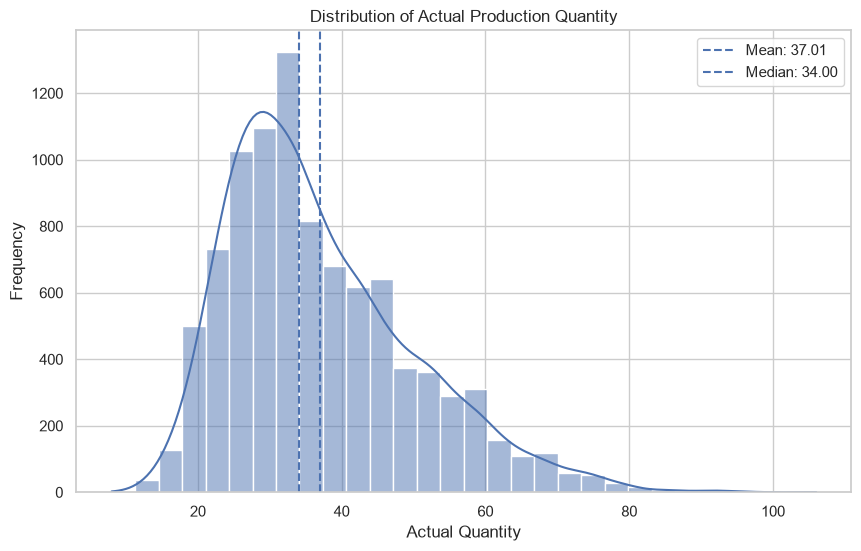

In [91]:
# Distribution of Actual Quantity

plt.figure(figsize=(10, 6))

ax = sns.histplot(
    df['actual_qty'],
    bins=30,
    kde=True
)

mean_val = df['actual_qty'].mean()
median_val = df['actual_qty'].median()

plt.axvline(
    mean_val,
    linestyle='--',
    label=f'Mean: {mean_val:.2f}'
)

plt.axvline(
    median_val,
    linestyle='--',
    label=f'Median: {median_val:.2f}'
)

plt.title('Distribution of Actual Production Quantity')
plt.xlabel('Actual Quantity')
plt.ylabel('Frequency')
plt.legend()
plt.show()

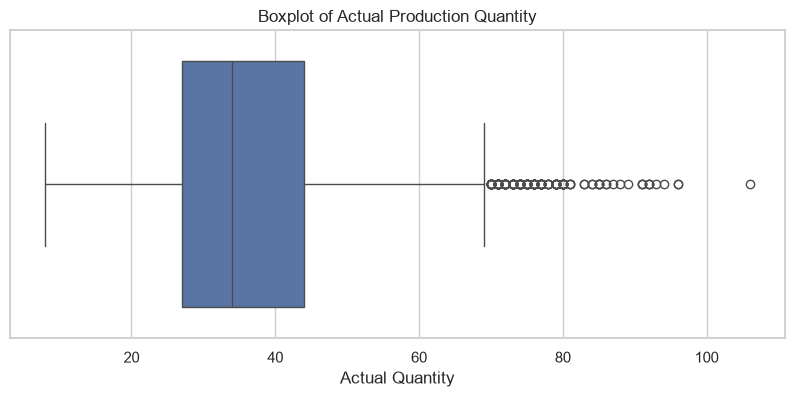

In [92]:
# Boxplot of Actual Quantity

plt.figure(figsize=(10, 4))

sns.boxplot(
    x=df['actual_qty']
)

plt.title('Boxplot of Actual Production Quantity')
plt.xlabel('Actual Quantity')
plt.show()

### 2.3.3 Normality Assessment of `actual_qty`

The distribution of `actual_qty` is examined using skewness, kurtosis, a Q–Q plot, and a statistical normality test. These diagnostics help describe whether the target distribution departs from a normal distribution.

The D’Agostino–Pearson test evaluates the null hypothesis that the observations follow a normal distribution. A small p-value provides evidence against this null hypothesis. However, the test can be sensitive to deviations from normality in large datasets, so the result should be interpreted alongside the visual diagnostics and descriptive statistics.

Normality of the target variable is not a general requirement for the tree-based regression models used in this project. This assessment is primarily descriptive and helps inform the interpretation of the data and any later residual diagnostics.

Target variable: actual_qty
Skewness: 0.9071
Excess kurtosis: 0.6822
D'Agostino-Pearson statistic: 1075.6792
P-value: 2.6256512557905495e-234
Conclusion: Reject the null hypothesis of normality.


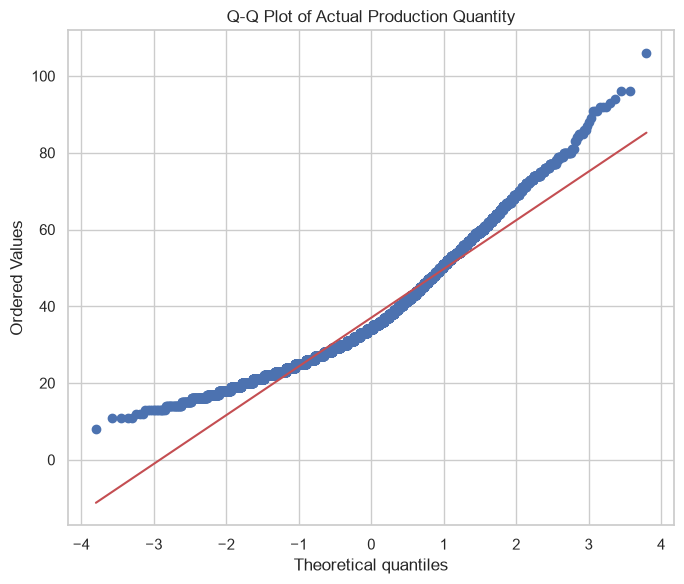

In [93]:

from scipy.stats import normaltest, skew, kurtosis
import scipy.stats as stats

target_data = df['actual_qty'].dropna()

# Descriptive measures
print("Target variable: actual_qty")
print("Skewness:", round(skew(target_data), 4))
print("Excess kurtosis:", round(kurtosis(target_data), 4))

# Normality test
statistic, p_value = normaltest(target_data)

print("D'Agostino-Pearson statistic:", round(statistic, 4))
print("P-value:", p_value)

alpha = 0.05

if p_value < alpha:
    print("Conclusion: Reject the null hypothesis of normality.")
else:
    print("Conclusion: Insufficient evidence to reject normality.")

# Q-Q plot
plt.figure(figsize=(7, 6))
stats.probplot(target_data, dist="norm", plot=plt)
plt.title("Q-Q Plot of Actual Production Quantity")
plt.tight_layout()
plt.show()


### 2.3.4 Log-Transformation Check

A logarithmic transformation is examined to determine whether it would make the distribution of `actual_qty` more symmetric.

The code applies `np.log1p()` to the target variable. This calculates the natural logarithm of one plus the original value and can be useful when examining variables with substantial right skewness.

A log transformation may reduce the influence of very large values and make a strongly skewed distribution easier to model. However, it changes the scale of the target, so predictions must be converted back to the original quantity scale when interpreting production output.

The original `actual_qty` distribution is already relatively balanced, with only a mild right tail. Therefore, a transformation should not be applied automatically. The final decision can be supported by comparing model performance during validation.


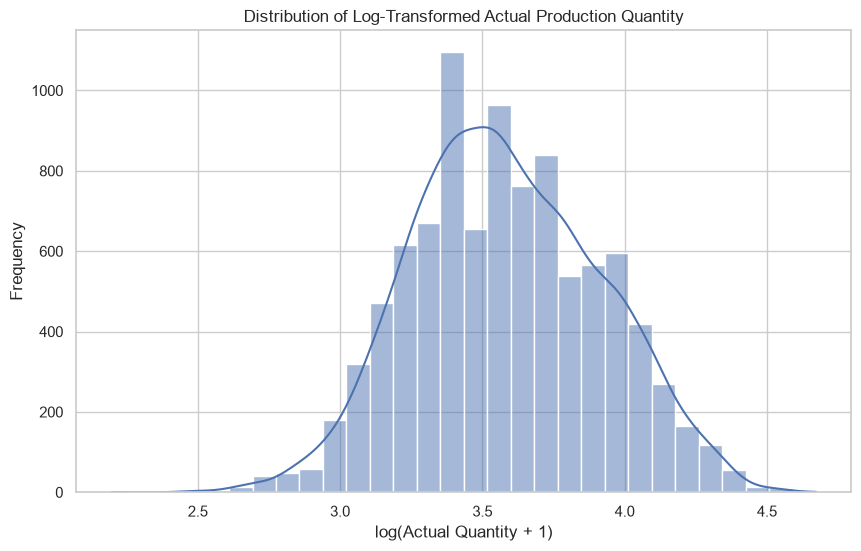

In [94]:
# Log-transformed target distribution

plt.figure(figsize=(10, 6))

sns.histplot(
    np.log1p(df['actual_qty']),
    bins=30,
    kde=True
)

plt.title('Distribution of Log-Transformed Actual Production Quantity')
plt.xlabel('log(Actual Quantity + 1)')
plt.ylabel('Frequency')
plt.show()

## 2.4 Temporal Patterns

Production output is examined across different time periods to identify possible trends, recurring patterns, and variations over time.

Temporal analysis is important because production quantities may vary with scheduling decisions, order requirements, workforce availability, and other time-related factors. Understanding these patterns helps determine whether time-related features may contribute to predicting `actual_qty`.

The analysis examines:

1. Weekly production trends.
2. Production differences across financial months.
3. Production differences across financial years.
4. Production by week number and week of the month.

The observed patterns are exploratory. Differences between time periods do not necessarily establish that time itself causes changes in production output.


### 2.4.1 Weekly Production Trend

The mean `actual_qty` is calculated for each `week_start_date` and displayed using a line plot.

Grouping the observations by production week provides a chronological view of how average production quantity changes throughout the study period.

The line plot helps identify sustained increases or decreases, short-term fluctuations, and periods with unusually high or low average production. These patterns can provide context for understanding production stability and potential changes in manufacturing activity.

For forecasting, the weekly trend also helps assess whether the data exhibits changes over time that a model may need to account for.

However, visible fluctuations should not automatically be interpreted as recurring patterns. Further validation is required to determine whether these patterns provide useful predictive information.

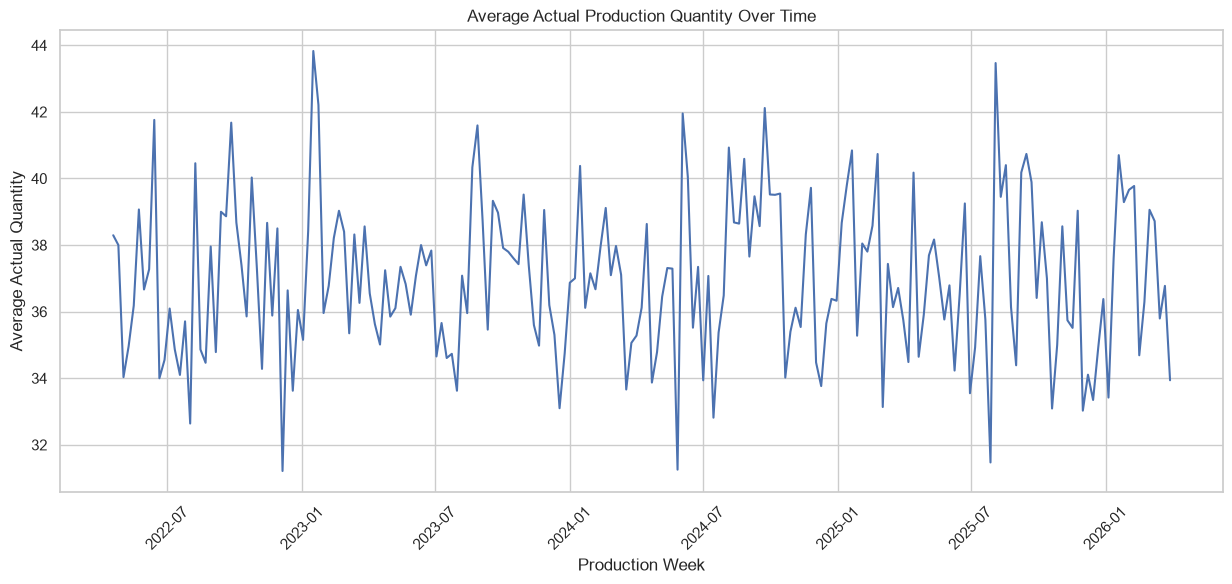

In [95]:
weekly_production = (
    df.groupby('week_start_date')['actual_qty']
      .mean()
      .reset_index()
)

plt.figure(figsize=(15, 6))

sns.lineplot(
    data=weekly_production,
    x='week_start_date',
    y='actual_qty'
)

plt.title('Average Actual Production Quantity Over Time')
plt.xlabel('Production Week')
plt.ylabel('Average Actual Quantity')
plt.xticks(rotation=45)
plt.show()

### 2.4.2 Production by Financial Month

Average actual production quantity is compared across financial months, with the months arranged from April to March.

This ordering follows the financial-year cycle and makes it easier to compare production across the complete financial year.

The average-value chart provides a direct comparison of typical output across months. The boxplot provides additional information about the median, spread, and potential extreme observations within each month.

These visualisations help investigate whether production quantities differ across financial months and whether some months show greater variability than others.

The recorded monthly averages vary from approximately 35 units in July and December to approximately 39 units in August. This indicates relatively modest differences in average output across the months.

However, monthly differences should be interpreted cautiously because they may also reflect variations in product mix, planned quantities, and the number of observations available for each period.


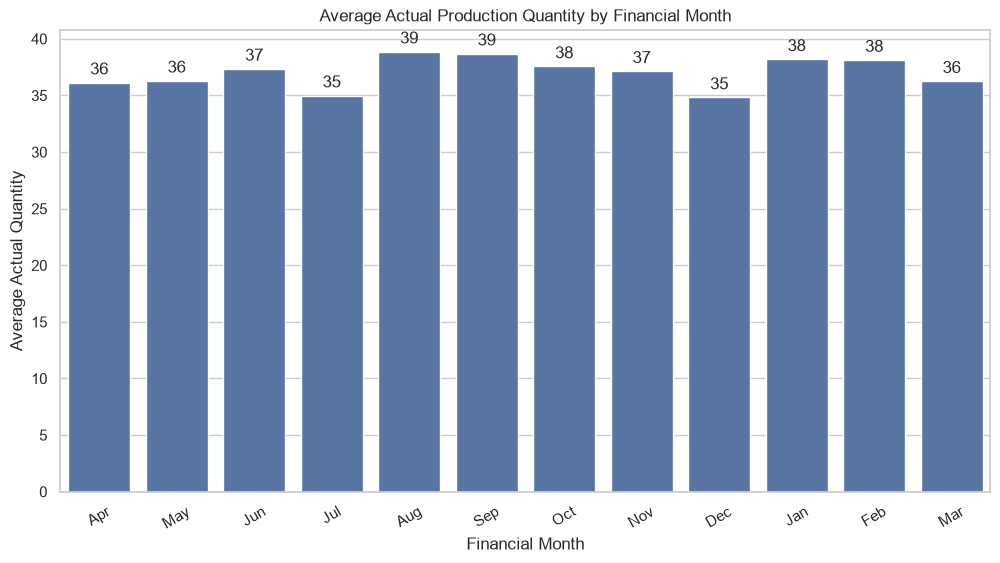

In [96]:
month_order = [
    'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep',
    'Oct', 'Nov', 'Dec', 'Jan', 'Feb', 'Mar'
]

monthly_production = (
    df.groupby('financial_month')['actual_qty']
      .mean()
      .reindex(month_order)
)

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    x=monthly_production.index,
    y=monthly_production.values
)

for p in ax.patches:
    ax.annotate(
        f'{p.get_height():.0f}',
        (p.get_x() + p.get_width() / 2.,
         p.get_height()),
        ha='center',
        va='center',
        xytext=(0, 9),
        textcoords='offset points'
    )

plt.title('Average Actual Production Quantity by Financial Month')
plt.xlabel('Financial Month')
plt.ylabel('Average Actual Quantity')
plt.xticks(rotation=30)
plt.show()

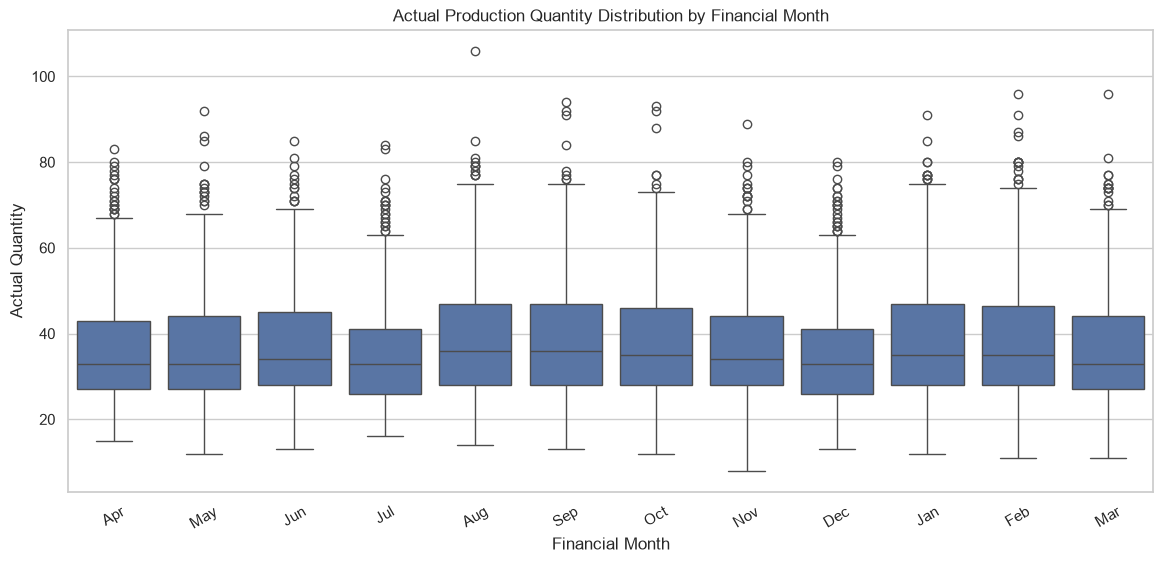

In [97]:
plt.figure(figsize=(14, 6))

sns.boxplot(
    data=df,
    x='financial_month',
    y='actual_qty',
    order=month_order
)

plt.title('Actual Production Quantity Distribution by Financial Month')
plt.xlabel('Financial Month')
plt.ylabel('Actual Quantity')
plt.xticks(rotation=30)
plt.show()

### 2.4.3 Production by Financial Year

The mean actual production quantity is calculated for each financial year and displayed using a bar chart.

Comparing financial-year averages provides a high-level view of whether production output has changed across the observation period.

Similar averages across years suggest that the overall annual mean has remained relatively stable, while larger differences could indicate changes that require further investigation.

The recorded financial-year averages are approximately 37 units, indicating relatively little variation in the overall annual mean.

Annual averages alone may conceal weekly fluctuations or changes in the mix of products and orders. Therefore, the results should be interpreted alongside the weekly and monthly analyses rather than being used as the only measure of temporal variation.


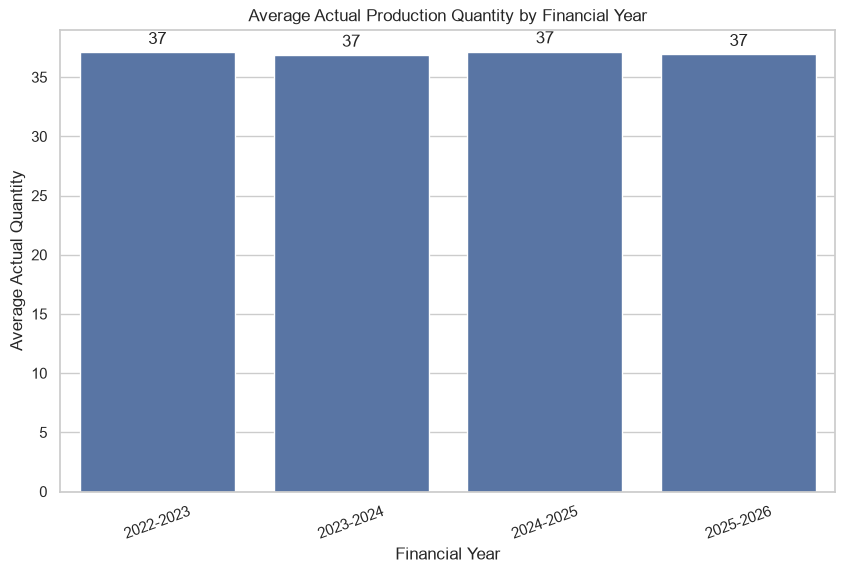

In [98]:
year_production = (
    df.groupby('financial_year')['actual_qty']
      .mean()
      .sort_index()
)

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x=year_production.index,
    y=year_production.values
)

for p in ax.patches:
    ax.annotate(
        f'{p.get_height():.0f}',
        (p.get_x() + p.get_width() / 2.,
         p.get_height()),
        ha='center',
        va='center',
        xytext=(0, 9),
        textcoords='offset points'
    )

plt.title('Average Actual Production Quantity by Financial Year')
plt.xlabel('Financial Year')
plt.ylabel('Average Actual Quantity')
plt.xticks(rotation=20)
plt.show()

### 2.4.4 Production by Week Number and Week of the Month

Production quantities are grouped by `week_no` and `week_of_month` to investigate whether average output varies according to position within a recurring calendar period.

The average production quantity for each week number is displayed using a line plot, while the average production quantity for each week of the month is displayed using a bar chart.

These comparisons help investigate whether output tends to differ at particular points in the calendar cycle. If such patterns are consistent, they may provide useful information for production scheduling and forecasting.

However, observations with the same week number may come from different years and financial periods. The resulting averages combine these observations and may conceal differences between individual years.

Therefore, the results should be treated as exploratory evidence rather than confirmation of a recurring production pattern.


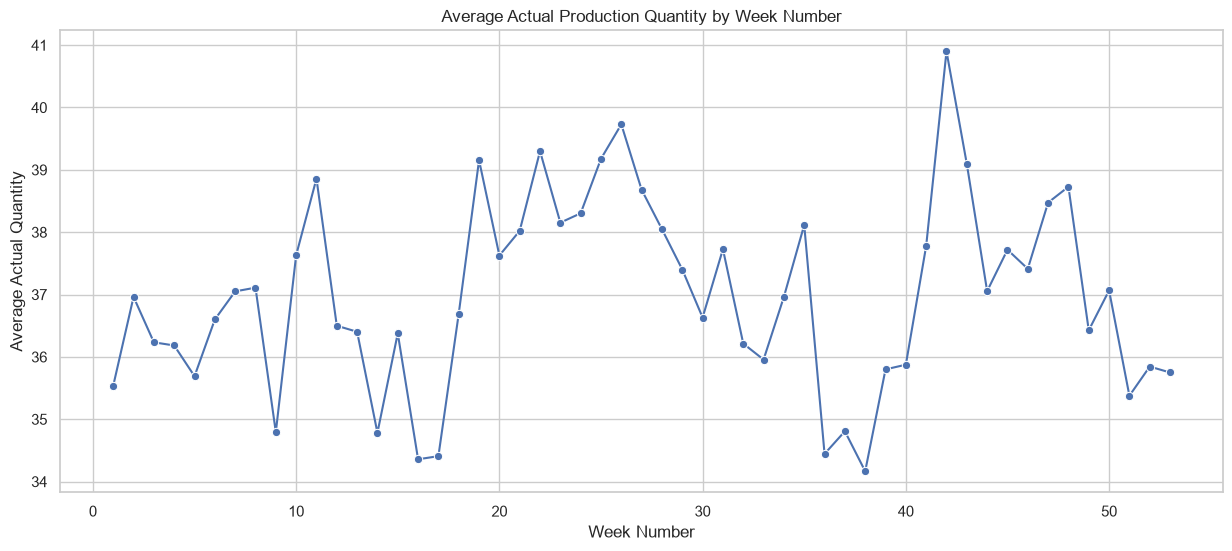

In [99]:
week_production = (
    df.groupby('week_no')['actual_qty']
      .mean()
)

plt.figure(figsize=(15, 6))

sns.lineplot(
    x=week_production.index,
    y=week_production.values,
    marker='o'
)

plt.title('Average Actual Production Quantity by Week Number')
plt.xlabel('Week Number')
plt.ylabel('Average Actual Quantity')
plt.show()

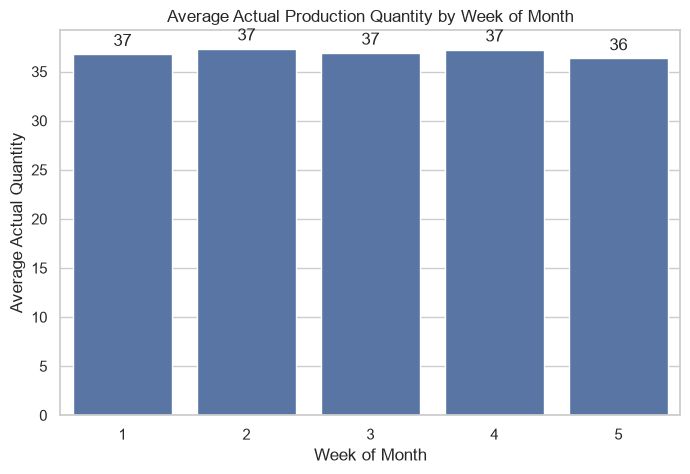

In [100]:
week_month_production = (
    df.groupby('week_of_month')['actual_qty']
      .mean()
)

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=week_month_production.index,
    y=week_month_production.values
)

for p in ax.patches:
    ax.annotate(
        f'{p.get_height():.0f}',
        (p.get_x() + p.get_width() / 2.,
         p.get_height()),
        ha='center',
        va='center',
        xytext=(0, 9),
        textcoords='offset points'
    )

plt.title('Average Actual Production Quantity by Week of Month')
plt.xlabel('Week of Month')
plt.ylabel('Average Actual Quantity')
plt.show()

## 2.5 Categorical Production Drivers

This section investigates whether average actual production quantity differs across categorical variables describing production units, products, sizes, grades, order types, and bottleneck conditions.

Categorical analysis helps identify groups with different production characteristics. Such differences may reflect variations in production requirements, product mix, resource allocation, or operational conditions.

The analysis covers:

1. Average actual production quantity across selected categories.
2. Item-level production summaries.
3. Production distributions by factory unit and size.
4. Comparison of records with and without a bottleneck flag.

Financial year and financial month are analysed separately in Section 2.4 to avoid repeating the temporal analysis.

The findings are descriptive. Differences between groups do not necessarily establish causation and should be interpreted alongside the number of observations in each category.


### 2.5.1 Average Actual Quantity by Category

Average actual production quantity is compared across the following categorical features:

- `factory_unit`
- `product_family`
- `size_id`
- `grade`
- `order_category`
- `bottleneck_flag`

The visualisations make it easier to compare typical output across the different categories and identify groups that may warrant further investigation.

For example, differences between factory units may reflect the distribution of orders or production responsibilities, while differences between product families or sizes may reflect different manufacturing requirements.

A higher average actual quantity does not automatically indicate better performance. It may instead reflect larger planned quantities or differences in the types of products being produced.

The results should therefore be interpreted alongside other relevant variables, particularly `planned_qty`, rather than using average output alone to rank categories.

In [101]:
categorical_features = [
    'factory_unit',
    'product_family',
    'size_id',
    'grade',
    'order_category',
    'bottleneck_flag'
]

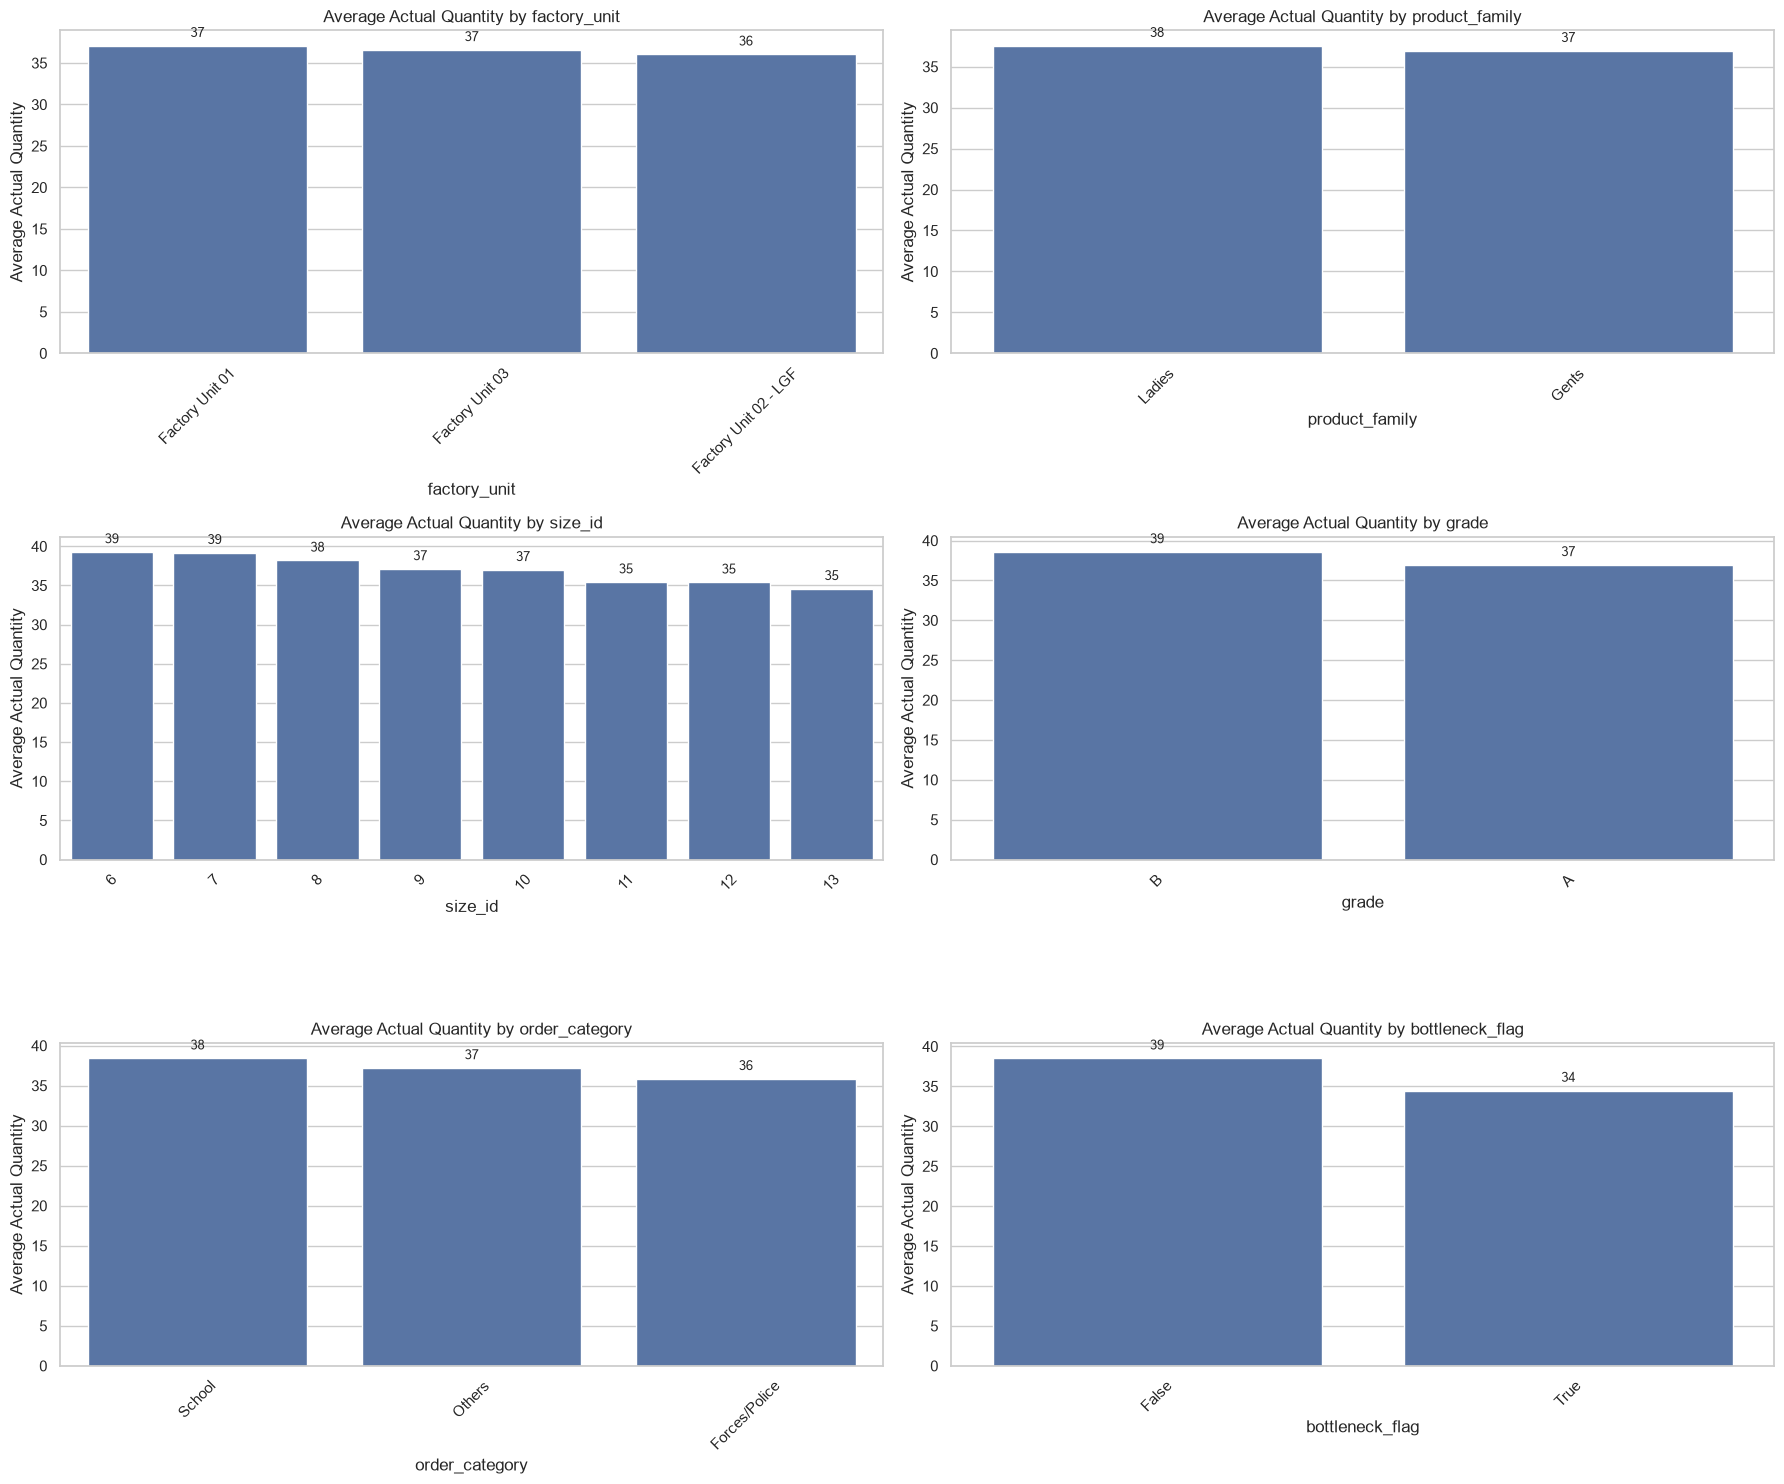

In [102]:
n_features = len(categorical_features)

n_cols = 2
n_rows = int(np.ceil(n_features / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(18, 5 * n_rows)
)

axes = np.asarray(axes).flatten()

for ax, feature in zip(axes, categorical_features):

    summary = (
        df.groupby(feature)['actual_qty']
          .mean()
          .sort_values(ascending=False)
    )

    sns.barplot(
        x=summary.index.astype(str),
        y=summary.values,
        ax=ax
    )

    for p in ax.patches:
        ax.annotate(
            f'{p.get_height():.0f}',
            (p.get_x() + p.get_width() / 2.,
             p.get_height()),
            ha='center',
            va='center',
            xytext=(0, 9),
            textcoords='offset points',
            fontsize=9
        )

    ax.set_title(
        f'Average Actual Quantity by {feature}'
    )

    ax.set_xlabel(feature)
    ax.set_ylabel('Average Actual Quantity')
    ax.tick_params(axis='x', rotation=45)

for ax in axes[n_features:]:
    ax.remove()

plt.tight_layout()
plt.show()

### 2.5.2 Item-Level Analysis

The `item_name` column is examined separately because it contains many distinct items.

For each item, the mean `actual_qty` and the number of observations are calculated. Sorting the results by observation count helps identify which items appear most frequently in the dataset.

The observation count is important when interpreting item-level averages. An average based on only a few records may be strongly influenced by individual observations, making it less reliable for comparison with an item that has many records.

This analysis provides an overview of the frequency of each item and the variation in its recorded production quantities.

Since the dataset contains 370 distinct items and many appear only a handful of times across the 207 production weeks, item-level results require careful interpretation.



In [103]:
# Item-level analysis

item_summary = (
    df.groupby('item_name')['actual_qty']
      .agg(['mean', 'count'])
      .sort_values('count', ascending=False)
)

item_summary.head(20)

,mean,count
item_name,,
DIYANA - L - BROWN,37.534884,43
ROGGER - L - BLACK,35.900000,40
BINOLI - BROWN,35.131579,38
D 707 - L - BROWN,32.756757,37
D 90 - L - WHITE,37.702703,37
DI SAFETY 551 - L - BROWN,34.810811,37
ROMI - L - BLACK,42.694444,36
D 707 - L - BLACK,32.277778,36
BOOT HIGHLEG BROWN ARTILLERY PATTERN - BROWN,41.514286,35


#### 2.5.2.1 Compare Items with Sufficient Observations

Items with at least 10 observations are retained for comparing average actual production quantity.

The filtered summary is used to identify the items with the highest and lowest average output among those meeting the minimum observation threshold.

Applying this threshold reduces the influence of averages based on very few records. However, it does not guarantee that all retained averages are equally reliable, and the results remain descriptive.

The analysis also highlights a modelling consideration: using `item_name` directly as a predictor could create a high-cardinality categorical variable, with many categories supported by relatively few observations.

Any use of item-level information should therefore be evaluated carefully during feature engineering and model validation.


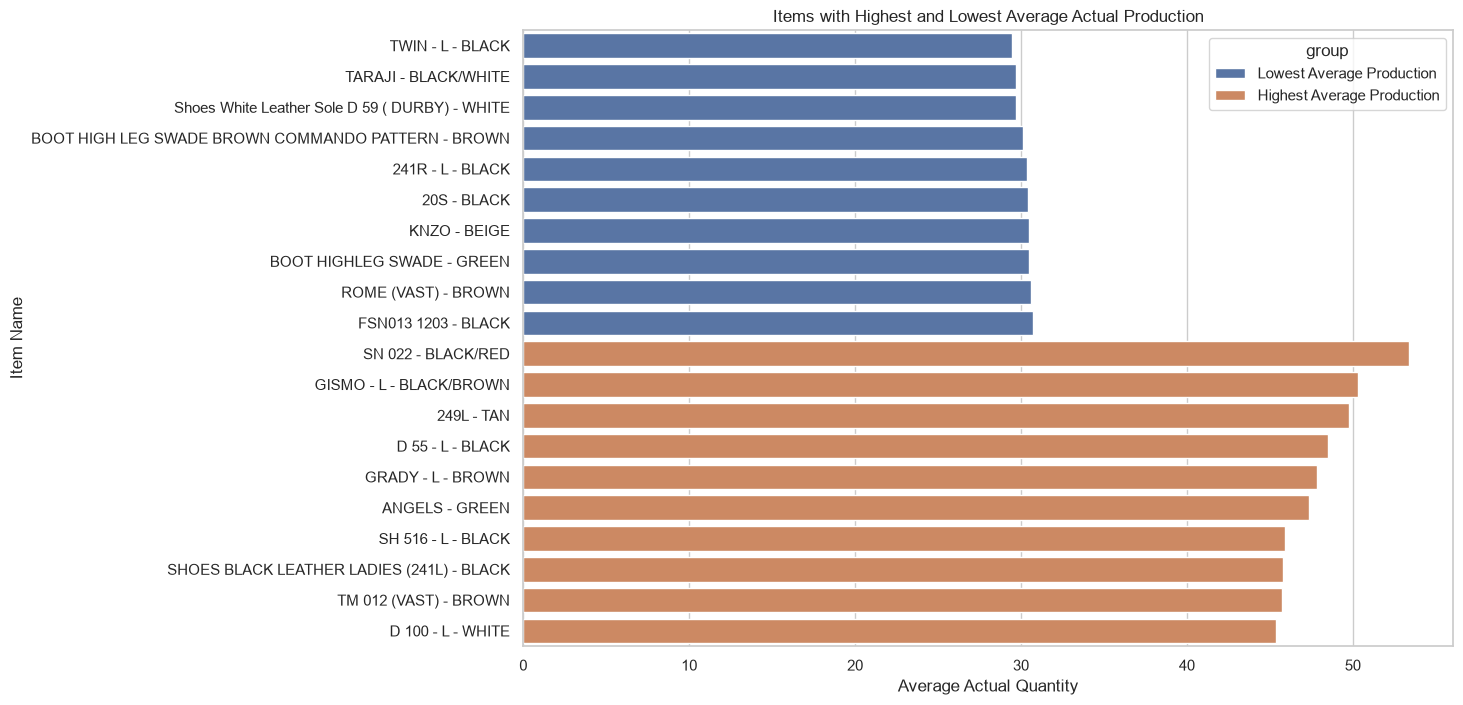

In [104]:
# Consider items with at least 10 observations

item_filtered = item_summary[
    item_summary['count'] >= 10
]

top_items = (
    item_filtered
    .sort_values('mean', ascending=False)
    .head(10)
)

bottom_items = (
    item_filtered
    .sort_values('mean', ascending=True)
    .head(10)
)

item_plot = pd.concat([
    bottom_items.assign(
        group='Lowest Average Production'
    ),
    top_items.assign(
        group='Highest Average Production'
    )
])

plt.figure(figsize=(12, 8))

sns.barplot(
    data=item_plot,
    x='mean',
    y=item_plot.index,
    hue='group'
)

plt.title(
    'Items with Highest and Lowest Average Actual Production'
)

plt.xlabel('Average Actual Quantity')
plt.ylabel('Item Name')
plt.show()

### 2.5.3 Distribution by Factory Unit and Size

Boxplots are used to examine the distribution of `actual_qty` across factory units and size identifiers.

Unlike a comparison of means alone, boxplots provide information about the median, spread, and potential extreme observations within each group.

The factory-unit comparison helps investigate whether production quantities differ across manufacturing units. The size comparison examines whether the distribution of output varies between shoe sizes.

Differences between groups may reflect variations in order allocation, product mix, planned quantities, or manufacturing requirements. Therefore, a higher median or wider distribution should not automatically be interpreted as better or worse production performance.

The number of observations in each group should also be considered when interpreting the results, especially where some groups contain substantially fewer records than others.


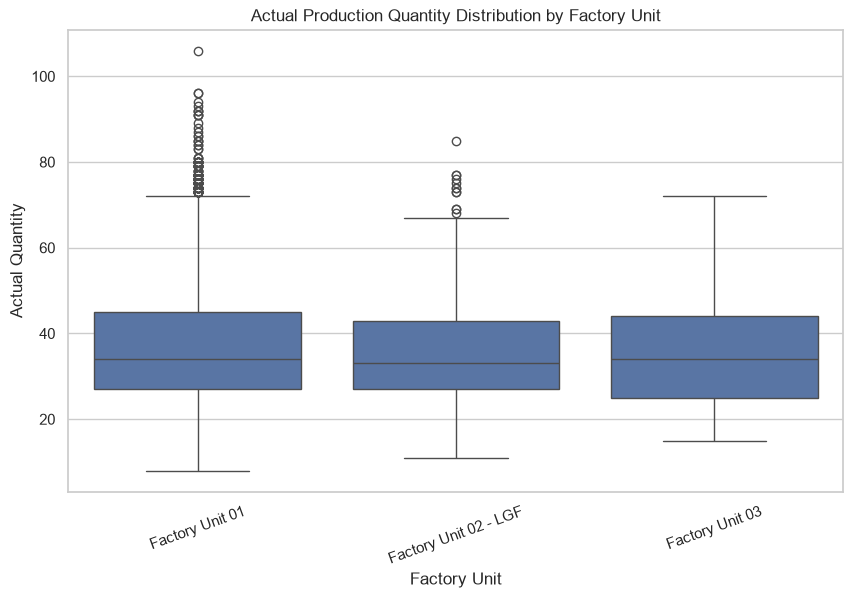

In [105]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='factory_unit',
    y='actual_qty'
)

plt.title('Actual Production Quantity Distribution by Factory Unit')
plt.xlabel('Factory Unit')
plt.ylabel('Actual Quantity')
plt.xticks(rotation=20)
plt.show()

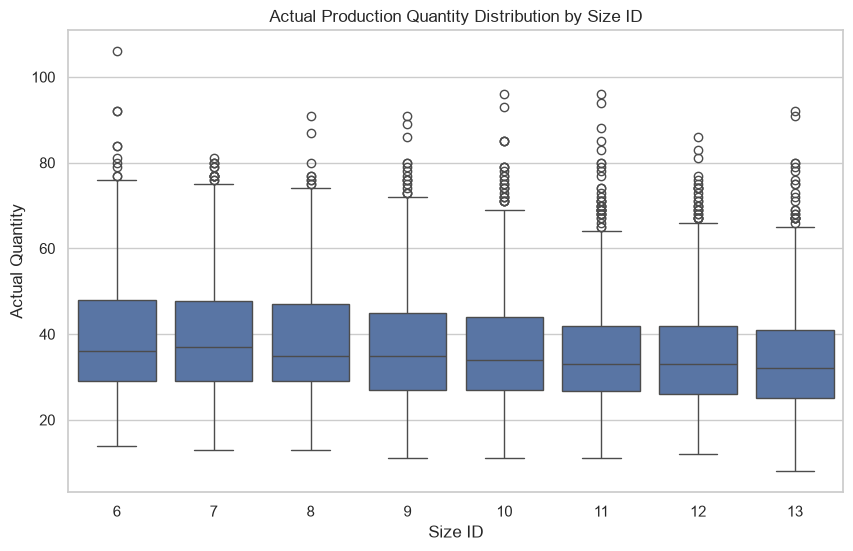

In [106]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='size_id',
    y='actual_qty'
)

plt.title('Actual Production Quantity Distribution by Size ID')
plt.xlabel('Size ID')
plt.ylabel('Actual Quantity')
plt.show()

### 2.5.4 Bottleneck Flag

The relationship between `bottleneck_flag` and actual production quantity is examined by calculating the observation count, mean, median, and standard deviation for each flag category.

- **Count:** Number of records in each group.
- **Mean:** Average actual production quantity.
- **Median:** Central production quantity, which is less sensitive to extreme values than the mean.
- **Standard deviation:** Degree of variation in actual production quantities within the group.

The results indicate average production of approximately 34 units for records flagged as bottlenecks and 39 units for records not flagged as bottlenecks.

This difference suggests an association between the bottleneck flag and production output in the observed records. However, the comparison does not establish that bottlenecks caused the lower average output.

Before using this variable in a machine learning model, it is also necessary to establish whether the flag is available at prediction time. If it is generated using information from completed production outcomes, it could introduce data leakage.


In [107]:
bottleneck_summary = (
    df.groupby('bottleneck_flag')['actual_qty']
      .agg(['count', 'mean', 'median', 'std'])
)

bottleneck_summary

,count,mean,median,std
bottleneck_flag,,,,
False,5983,38.507271,36.0,13.127614
True,3512,34.464692,32.0,12.518350


## 2.6 Numerical Drivers and Correlation

This section investigates relationships between numerical variables and the target variable, `actual_qty`.

Numerical analysis helps determine whether production quantities tend to increase or decrease alongside changes in planning quantities, workforce measures, machine counts, production duration, and time-related variables.

The analysis includes:

1. Selection of numerical features for examination.
2. Average actual quantity across feature deciles.
3. Correlation between numerical features and the target.
4. Multicollinearity among predictor variables.

These analyses help inform feature selection and model development. However, correlations and grouped averages describe associations in the observed data and do not establish causal relationships.


### 2.6.1 Numerical Features Under Analysis

A selected group of numerical variables is examined to understand their potential relationships with `actual_qty`.

The selected features are:

- `planned_qty`
- `rate`
- `no_of_workers`
- `working_hours`
- `machine_count`
- `total_duration_per_shoe_mins`
- `week_no`
- `week_of_month`

These variables represent different aspects of production planning, resources, production characteristics, and time.

The `machine_capacity_per_day` column is excluded because it has a constant value of 200 and therefore provides no variation for correlation analysis.

Only variables available in the current dataset are included. The final modelling features must also be checked for relevance and availability at prediction time, and variables derived from the actual production outcome must be excluded to prevent data leakage.

In [108]:
numeric_features = [
    'planned_qty',
    'rate',
    'no_of_workers',
    'working_hours',
    'machine_count',
    'total_duration_per_shoe_mins',
    'week_no',
    'week_of_month'
]

print("Numerical features used for EDA:")
print(numeric_features)

Numerical features used for EDA:
['planned_qty', 'rate', 'no_of_workers', 'working_hours', 'machine_count', 'total_duration_per_shoe_mins', 'week_no', 'week_of_month']


### 2.6.2 Average Actual Quantity Across Feature Deciles

The numerical features are divided into deciles to examine how average `actual_qty` varies across different ranges of each feature.

Deciles divide the observations into approximately 10 groups according to the distribution of a numerical variable. Comparing the mean actual production quantity across these groups helps reveal patterns that may not be apparent from a single correlation coefficient.

For example, average output may increase as a feature rises, decrease across higher values, or remain relatively stable across the groups.

This analysis helps investigate whether relationships may be nonlinear or whether production output differs across low, medium, and high ranges of a feature.

The results remain descriptive. Differences between deciles do not establish that the feature causes changes in production quantity, and the patterns should be assessed further during model development.


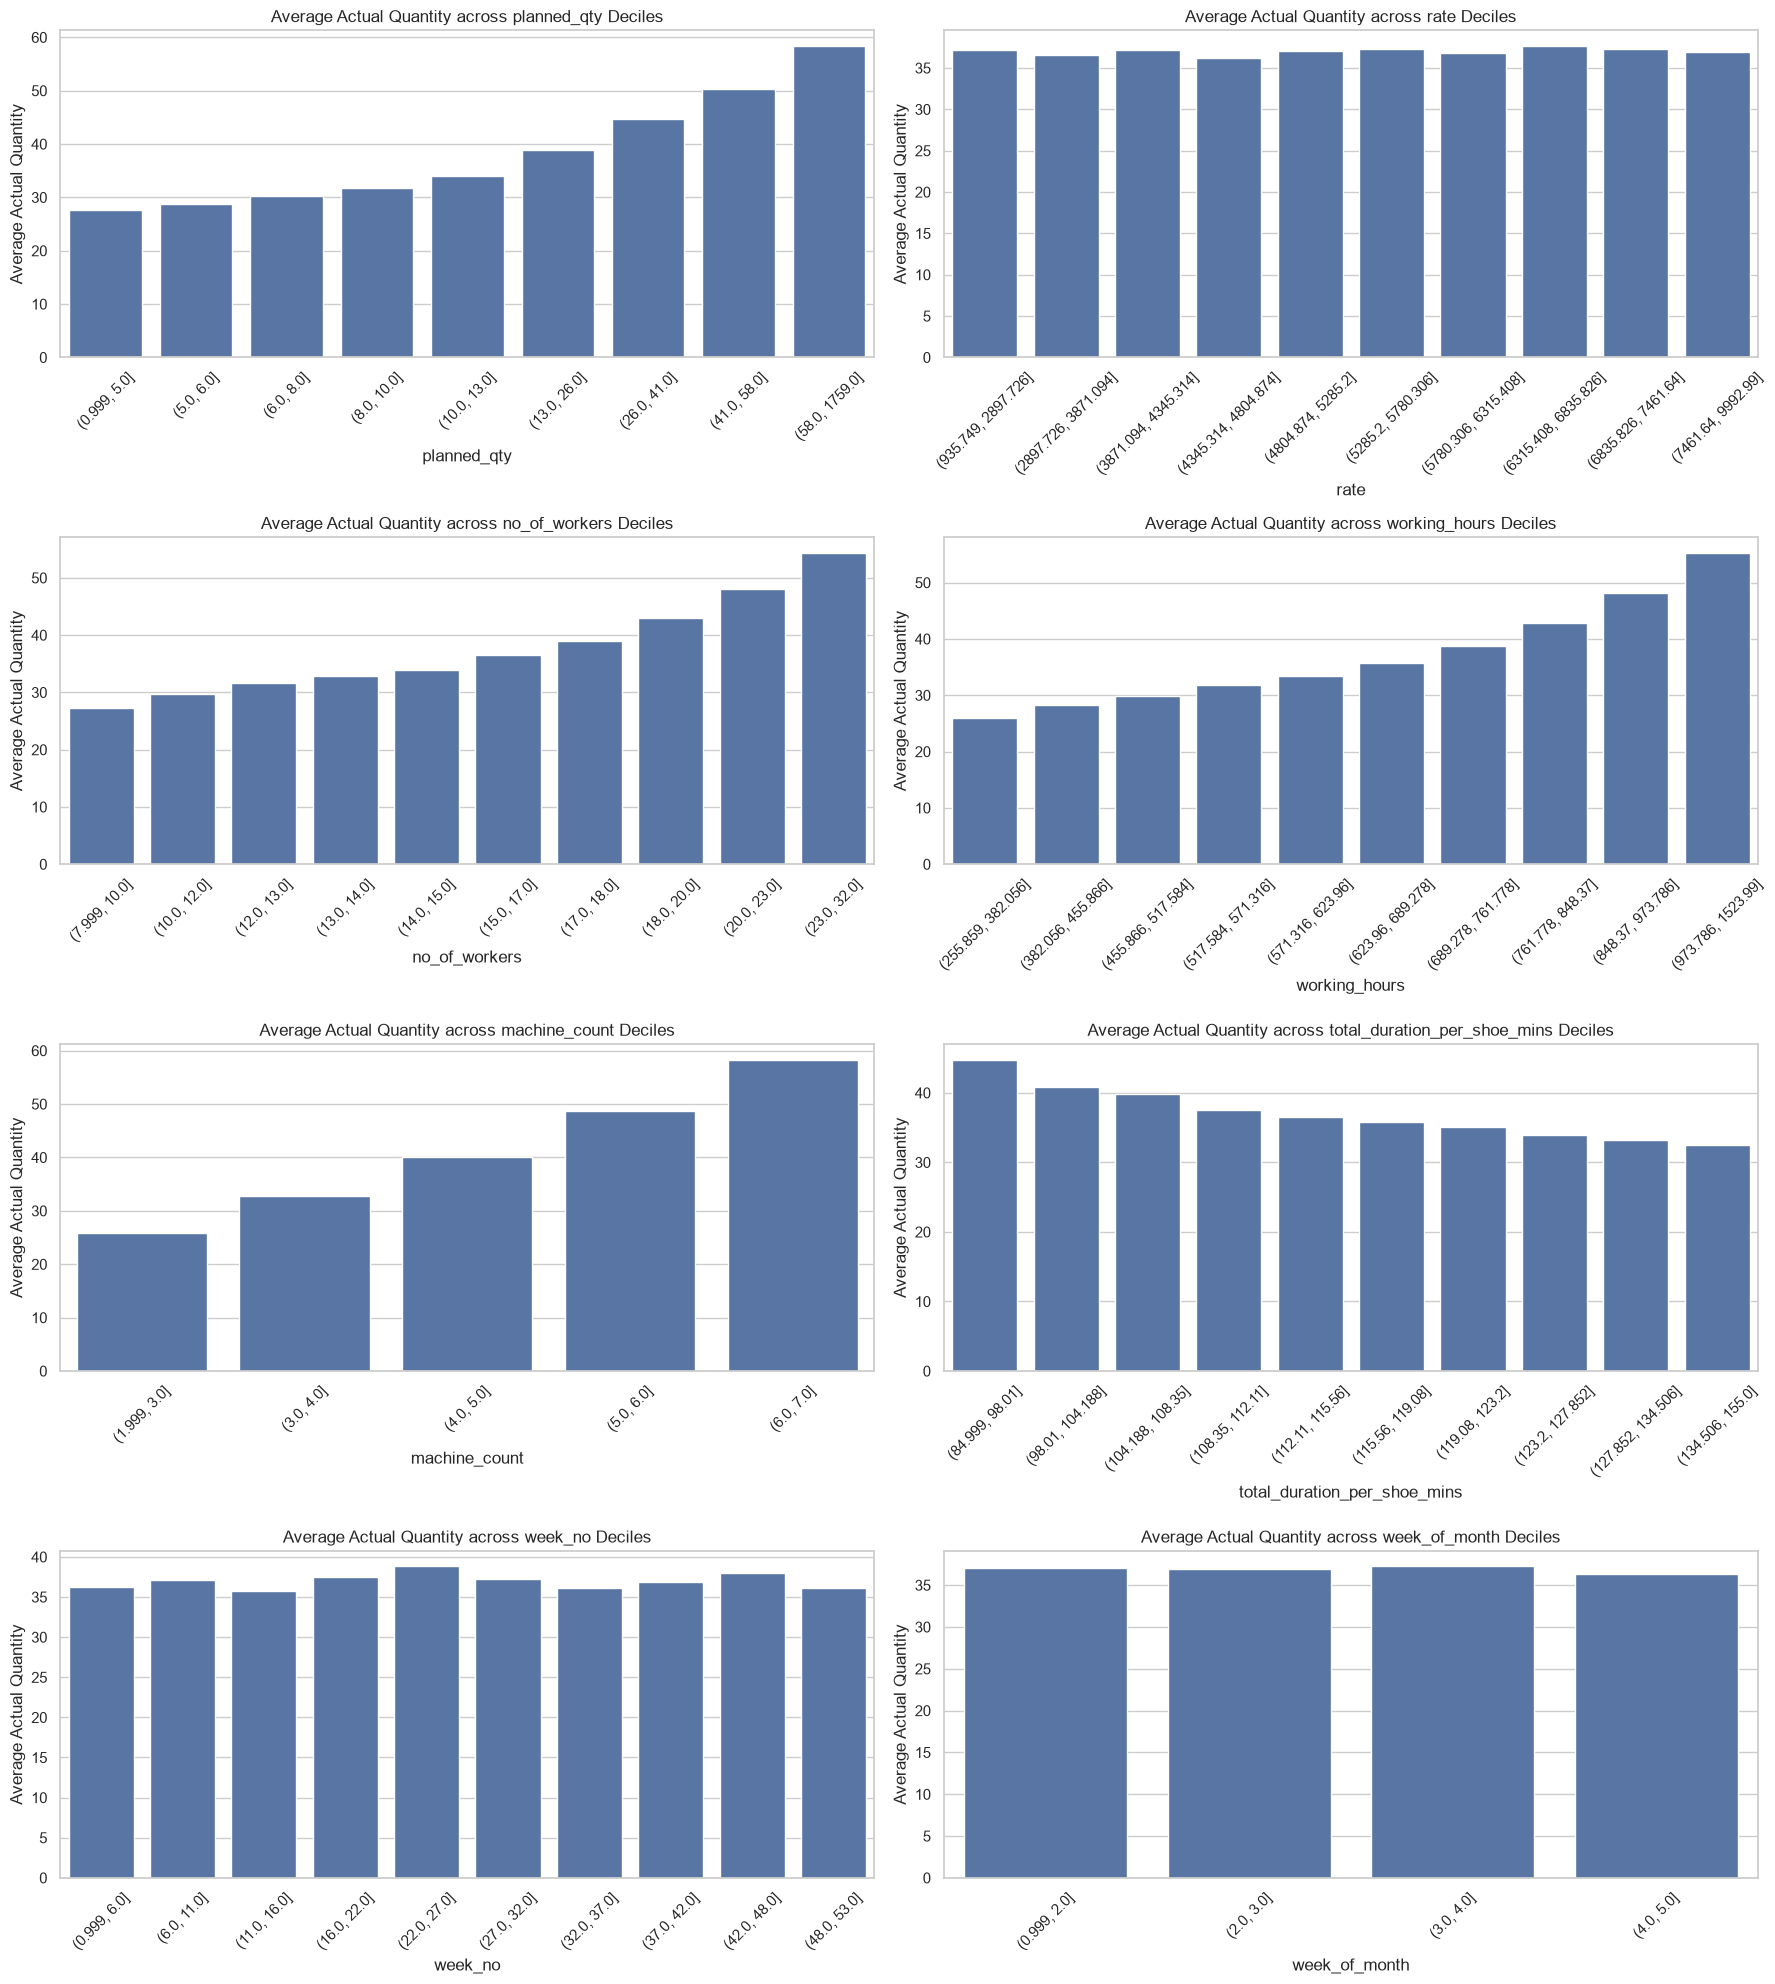

In [109]:
n_features = len(numeric_features)

n_cols = 2
n_rows = int(np.ceil(n_features / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(18, 5 * n_rows)
)

axes = np.asarray(axes).flatten()

for ax, feature in zip(axes, numeric_features):

    temp = df[
        [feature, 'actual_qty']
    ].dropna().copy()

    try:
        temp['bin'] = pd.qcut(
            temp[feature],
            q=10,
            duplicates='drop'
        )

        summary = (
            temp.groupby(
                'bin',
                observed=True
            )['actual_qty']
            .mean()
        )

        sns.barplot(
            x=summary.index.astype(str),
            y=summary.values,
            ax=ax
        )

        ax.set_title(
            f'Average Actual Quantity across {feature} Deciles'
        )

        ax.set_xlabel(feature)
        ax.set_ylabel('Average Actual Quantity')

        ax.tick_params(
            axis='x',
            rotation=45
        )

    except ValueError:

        ax.scatter(
            temp[feature],
            temp['actual_qty'],
            alpha=0.35
        )

        ax.set_title(
            f'{feature} vs Actual Quantity'
        )

        ax.set_xlabel(feature)
        ax.set_ylabel('Actual Quantity')

for ax in axes[n_features:]:
    ax.remove()

plt.tight_layout()
plt.show()

### 2.6.3 Correlation with the Target

A correlation matrix is calculated for the selected numerical features and `actual_qty`. A heatmap is used to display the pairwise correlation coefficients.

The Pearson correlation coefficient ranges from -1 to +1:

- **Positive correlation:** Higher values of one variable tend to be associated with higher values of the other.
- **Negative correlation:** Higher values of one variable tend to be associated with lower values of the other.
- **Correlation near zero:** Little or no linear relationship is evident.

The heatmap provides a convenient way to compare relationships between numerical variables and identify pairs that may contain overlapping information.

Correlation can help identify potential predictors, but it measures linear association and may not capture nonlinear relationships. A weak correlation does not necessarily mean that a variable has no predictive value.

The correlation matrix must also be interpreted with care when variables are derived from the target, because mathematical relationships can create misleadingly strong associations.


In [110]:
# Numerical features selected for correlation analysis (target included)
correlation_features = numeric_features
correlation_columns = correlation_features + ['actual_qty']

correlation_matrix = df[correlation_columns].corr()

print("Variables included in correlation analysis:")
print(correlation_columns)

Variables included in correlation analysis:
['planned_qty', 'rate', 'no_of_workers', 'working_hours', 'machine_count', 'total_duration_per_shoe_mins', 'week_no', 'week_of_month', 'actual_qty']


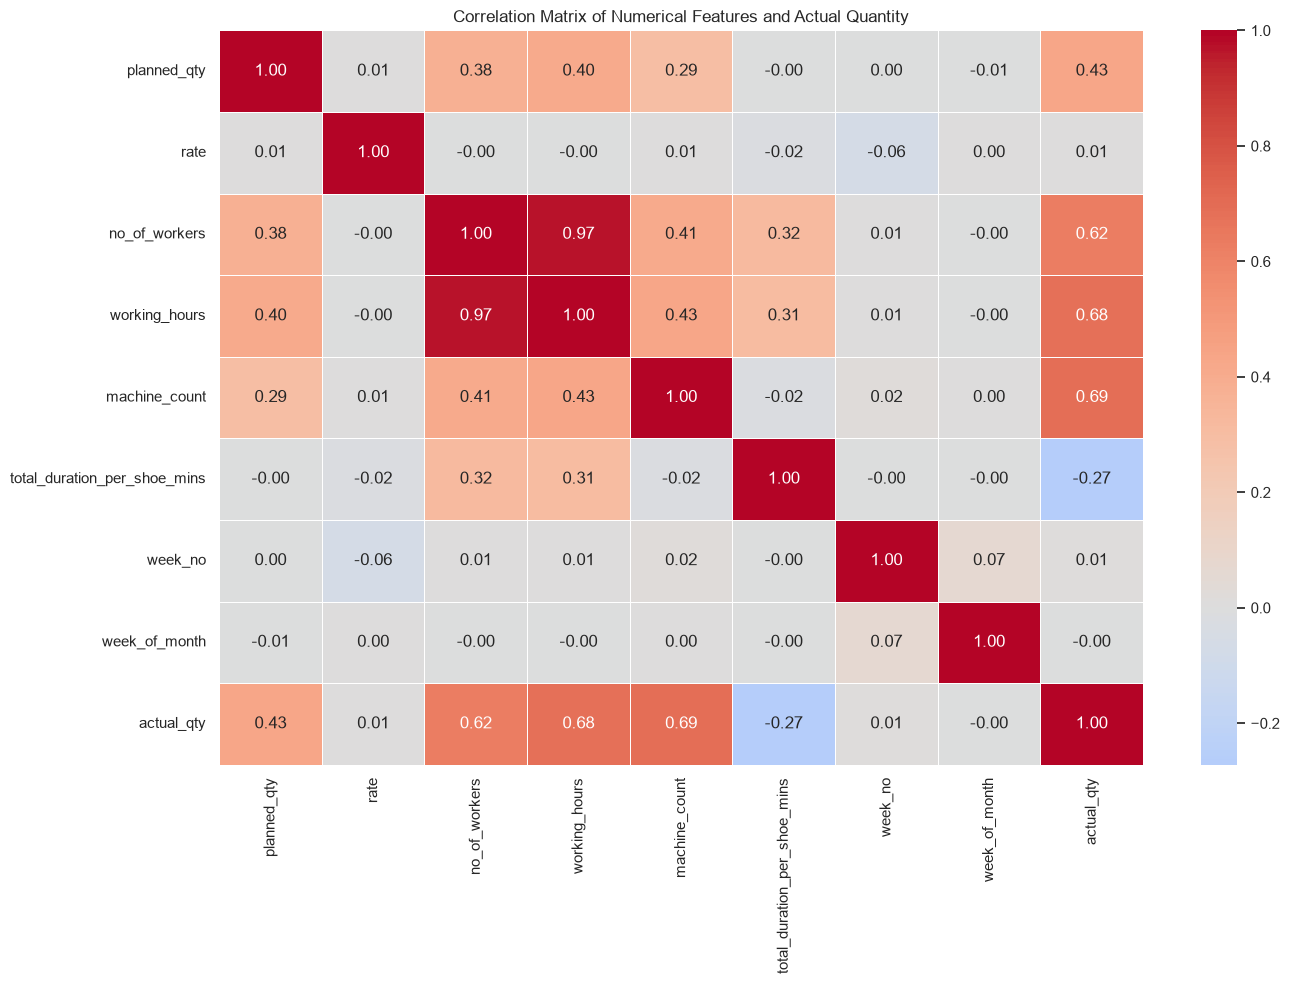

In [111]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Correlation Matrix of Numerical Features and Actual Quantity")
plt.tight_layout()
plt.show()

#### 2.6.3.1 Interpret Correlations with `actual_qty`

The correlation between each numerical feature and `actual_qty` is extracted and sorted to make the relative relationships easier to compare.

The results show the strongest positive correlations for:

- `machine_count`: approximately 0.69.
- `working_hours`: approximately 0.68.
- `no_of_workers`: approximately 0.62.

`planned_qty` has a moderate positive correlation of approximately 0.43, while `total_duration_per_shoe_mins` has a negative correlation of approximately -0.27. The correlations for `rate`, `week_no`, and `week_of_month` are close to zero.

These results suggest that machine count and workforce-related measures are associated with actual production quantity in the observed data. However, the variables may also be related to each other, so their individual correlations should not be interpreted in isolation.

The findings provide an initial basis for feature selection. The final usefulness of each variable should be assessed through model validation, while ensuring that predictors do not contain information derived from the actual production outcome.

In [112]:
target_correlations = (
    correlation_matrix['actual_qty']
    .drop('actual_qty')
    .sort_values(ascending=False)
)

print("Correlation of Numerical Features with Actual Quantity:")
display(target_correlations.to_frame(name='Correlation with actual_qty'))

Correlation of Numerical Features with Actual Quantity:


,Correlation with actual_qty
machine_count,0.689623
working_hours,0.682933
no_of_workers,0.623795
planned_qty,0.431519
week_no,0.014598
rate,0.006793
week_of_month,-0.001624
total_duration_per_shoe_mins,-0.272027


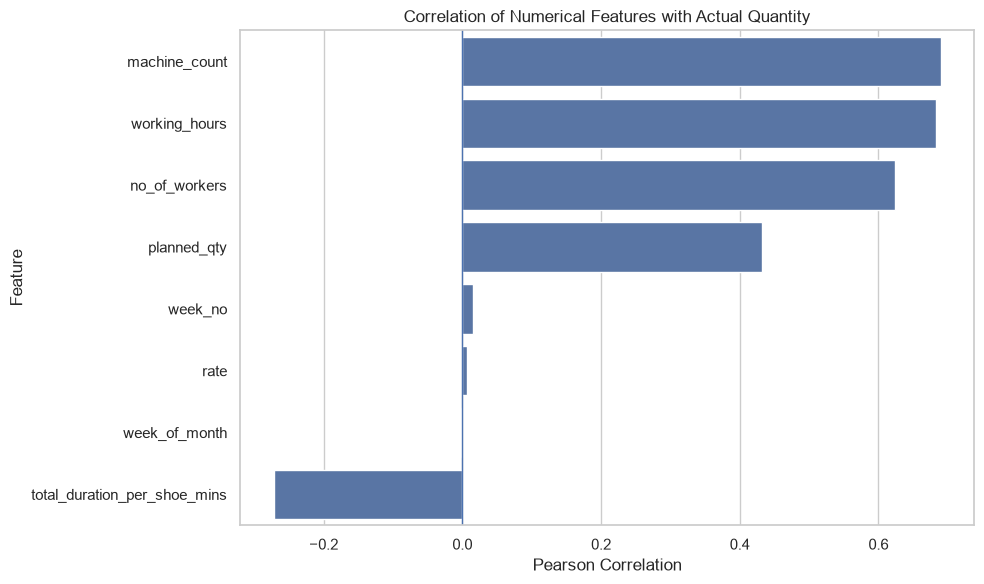

In [113]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=target_correlations.values,
    y=target_correlations.index
)

plt.axvline(0, linewidth=1)

plt.title("Correlation of Numerical Features with Actual Quantity")
plt.xlabel("Pearson Correlation")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()


### 2.6.4 Multicollinearity Among Predictors

Multicollinearity occurs when two or more predictor variables are strongly correlated with one another.

The absolute correlation matrix is examined to identify pairs of numerical predictors with an absolute correlation of at least 0.80. This threshold is used as a screening rule to highlight potentially redundant variables.

The results identify `no_of_workers` and `working_hours` as having a very high correlation of approximately 0.97. This indicates that the two variables carry strongly overlapping information in the observed data.

High multicollinearity can make coefficient estimates and their interpretation less stable in models such as linear regression. Its effects can differ in tree-based models, but strongly related features may still complicate interpretation.

The correlation result does not automatically mean that one variable must be removed. The final decision should consider each variable's operational meaning, availability at prediction time, and contribution to model performance during validation.

In [114]:
# Correlation among predictor variables only
predictor_corr = df[correlation_features].corr().abs()

# Select upper triangle of correlation matrix
upper_triangle = predictor_corr.where(
    np.triu(
        np.ones(predictor_corr.shape),
        k=1
    ).astype(bool)
)

# Identify pairs with correlation greater than 0.80
high_corr_pairs = (
    upper_triangle
    .stack()
    .reset_index()
)

high_corr_pairs.columns = [
    'Feature 1',
    'Feature 2',
    'Absolute Correlation'
]

high_corr_pairs = high_corr_pairs[
    high_corr_pairs['Absolute Correlation'] >= 0.80
].sort_values(
    'Absolute Correlation',
    ascending=False
)

print("Highly correlated predictor pairs (|r| >= 0.80):")

display(high_corr_pairs)

Highly correlated predictor pairs (|r| >= 0.80):


,Feature 1,Feature 2,Absolute Correlation
19,no_of_workers,working_hours,0.969682


###  Investigating Linear and Nonlinear Relationships

Correlation coefficients summarise the strength and direction of linear relationships, but they may not capture nonlinear patterns. A predictor can have a weak Pearson correlation with `actual_qty` while still having a useful nonlinear relationship with the target.

Scatter plots with LOWESS smoothing are used to examine the relationship between selected numerical predictors and actual production quantity. A roughly straight smoothed trend suggests an approximately linear relationship over the observed range, while a curved trend may indicate nonlinearity. These plots provide exploratory evidence rather than proof of a particular functional relationship.

The findings can help explain why both linear models and tree-based models are considered during model selection.

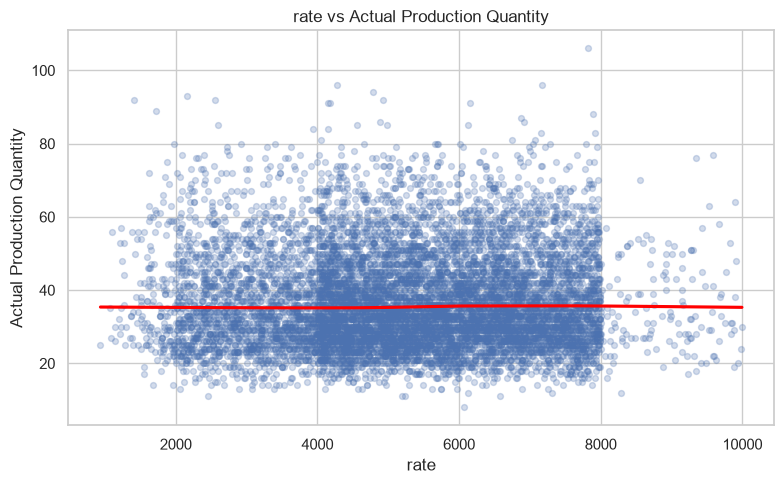

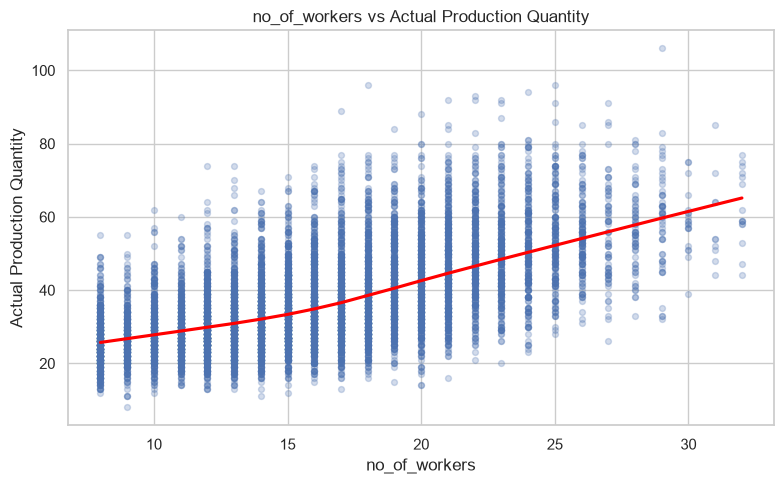

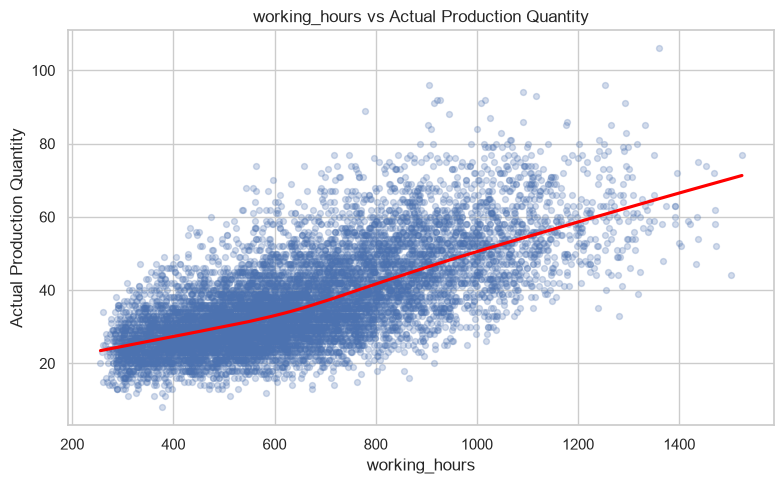

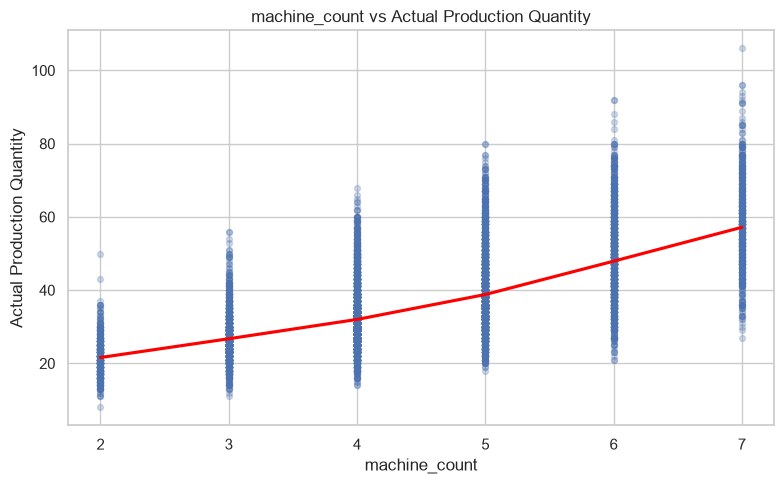

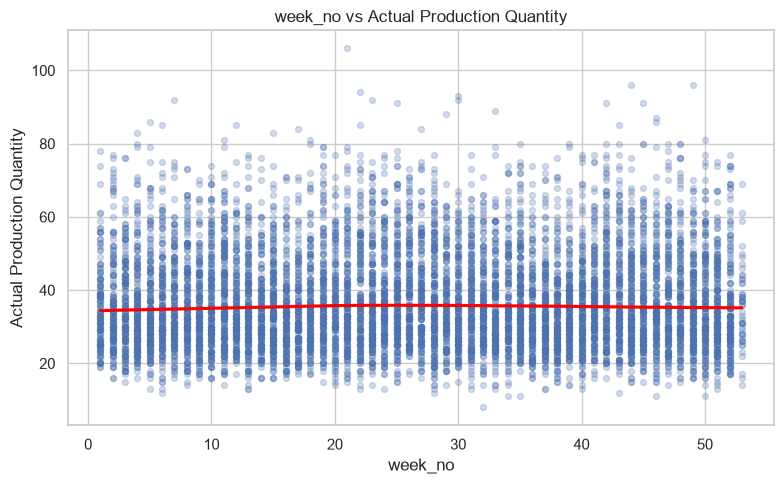

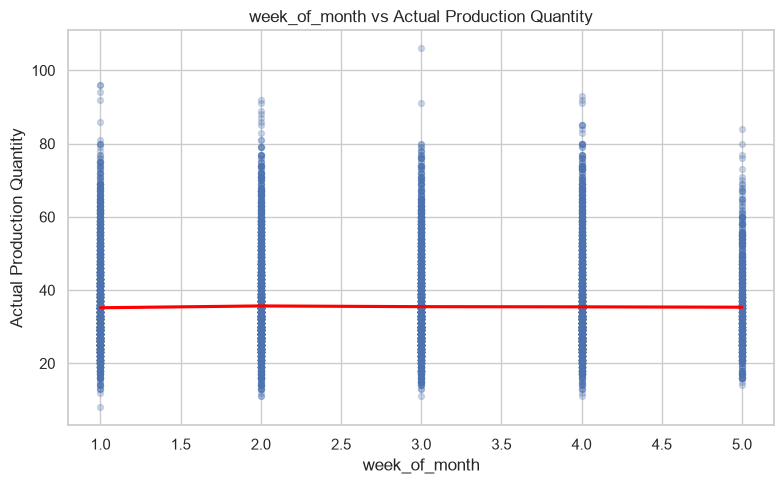

In [115]:

# Select numerical predictors that are available before production.
# Exclude target-derived or potentially leakage-related variables.
pattern_features = [
    'rate',
    'no_of_workers',
    'working_hours',
    'machine_count',
    'week_no',
    'week_of_month'
]

for col in pattern_features:
    plt.figure(figsize=(8, 5))

    sns.regplot(
        data=df,
        x=col,
        y='actual_qty',
        lowess=True,
        scatter_kws={'alpha': 0.25, 's': 18},
        line_kws={'color': 'red'}
    )

    plt.title(f'{col} vs Actual Production Quantity')
    plt.xlabel(col)
    plt.ylabel('Actual Production Quantity')
    plt.tight_layout()
    plt.show()


## 2.7 Key EDA Findings

The exploratory analysis provides an overview of the dataset's quality, target distribution, temporal patterns, categorical differences, and numerical relationships. These findings help guide the next stages of feature engineering and machine learning.

### 2.7.1 Data Quality and Structure

The dataset contains 9,495 records across 22 columns and represents 207 production weeks from April 2022 to March 2026.

The documented checks show no missing values, no exact duplicate records, and no zero or negative values in `planned_qty` or `actual_qty`. The `machine_capacity_per_day` column has a constant value of 200 and therefore provides no variation for distinguishing between production records.

### 2.7.2 Target Variable: `actual_qty`

Actual production quantity ranges from 8 to 106, with a mean of approximately 37 and a median of 34. Its distribution is relatively balanced, with a mild right tail.

These characteristics suggest that modelling `actual_qty` on its original scale is a reasonable starting point. A logarithmic transformation should only be considered if model validation provides evidence that it improves predictive performance.

### 2.7.3 Planned and Actual Production

`planned_qty` has a mean of approximately 38 and a median of 10, indicating a strongly right-skewed distribution. In comparison, `actual_qty` has a mean of approximately 37 and a median of 34.

The correlation between planned and actual quantities is approximately 0.43, indicating a moderate positive linear relationship rather than a close one-to-one relationship.

The median production gap is negative under the formula `planned_qty - actual_qty`, indicating that actual production exceeds planned quantity in more than half of the observed records. Because `production_gap_qty` is derived directly from the target and planned quantity, it must not be used as a predictor when forecasting `actual_qty`.

### 2.7.4 Temporal Patterns

Average production is relatively similar across financial years, at approximately 37 units. Monthly averages show modest variation, ranging from approximately 35 units in July and December to approximately 39 units in August.

These results suggest that the observed aggregate temporal differences are relatively small. Nevertheless, time-related variables can still be evaluated during model validation rather than being excluded solely on the basis of their average patterns.

### 2.7.5 Categorical Production Drivers

Average output differs only modestly across several categorical groups, including factory unit, product family, grade, size, and order category, with averages generally around 35–39 units.

The bottleneck comparison shows an average of approximately 34 units for flagged records and 39 units for non-flagged records. This difference is worth investigating, but it does not establish a causal effect.

The observations are also imbalanced across factory units: Factory Unit 01 contains 8,921 records, Factory Unit 02 – LGF contains 525, and Factory Unit 03 contains 49. Comparisons involving the least-represented unit should therefore be interpreted cautiously.

### 2.7.6 Numerical Relationships and Redundancy

The strongest positive numerical correlations with `actual_qty` are observed for `machine_count` (approximately 0.69), `working_hours` (approximately 0.68), and `no_of_workers` (approximately 0.62).

`total_duration_per_shoe_mins` has a negative correlation of approximately -0.27. The relationships for `rate`, `week_no`, and `week_of_month` are close to zero in the linear correlation analysis.

`no_of_workers` and `working_hours` are highly correlated with each other, at approximately 0.97. Their overlapping information should be considered when selecting predictors, particularly for models where coefficient interpretation is important.

### 2.7.7 Item-Level Observations

The dataset contains 370 distinct items, and many items have relatively few observations. Item-level averages based on limited records may not be reliable enough for direct comparison.

Using `item_name` as a predictor could also create a high-cardinality categorical feature. Any use of item-level information should therefore be evaluated carefully and validated against later observations.

### 2.7.8 Implications for Machine Learning

The EDA suggests that workforce and machine-related variables may provide useful information for predicting `actual_qty`. Planning quantity may also be relevant, although its relationship with actual output is moderate.

Before modelling, predictors must be checked for availability at the time a forecast is generated. Variables calculated from completed production outcomes must be excluded to prevent data leakage.

The modelling stage should use a chronological train-test split to preserve the forecasting order. Candidate models should be evaluated using appropriate regression metrics, such as MAE, RMSE, and R², and compared against a simple baseline.

Overall, the EDA provides a foundation for selecting candidate predictors and designing a reliable evaluation process. The usefulness of individual variables and models must ultimately be confirmed through validation rather than inferred from exploratory relationships alone.
